# BEYOND THE CRASH — Aviation Accident Analysis

## Project Introduction

This notebook examines patterns in recorded aviation accidents, including flight phases, weather conditions, investigation findings, aircraft characteristics, and fatal outcomes. The analysis is descriptive: it compares outcomes **among recorded accidents** and does not estimate accident risk per flight or establish causation.

**Dataset Name:** NTSB Aviation Accident Investigation Data (CAROL)

**Source:** National Transportation Safety Board (NTSB)

**Source Link:** https://my.ntsb.gov/aviation

**Dataset File:** CAROL_Aviation_Corrected.csv

## Problem Definition and Research Questions

1. **The Deadliest Moment:** Is the most frequently reported flight phase also associated with the highest proportion of fatal accidents?
2. **The Weather Paradox:** Are accidents recorded under VMC necessarily associated with less severe outcomes than accidents under IMC?
3. **Human Error or Mechanical Failure?:** Which contributing-factor categories appear most frequently in official investigation findings?
4. **Does the Aircraft Matter?:** How do recorded fatal-outcome proportions differ across aircraft categories and engine configurations?
5. **The Survival Paradox:** Can an aircraft sustain substantial or destructive damage while recording zero fatalities?
6. **The Hidden Pattern:** How do documented investigation findings differ between fatal and nonfatal accidents?

## 1. Dataset Loading and Initial Exploration


### Dataset Description and Motivation
The dataset contains aviation accident records with event dates, aircraft characteristics, flight phases, weather information, recorded injuries, aircraft damage, and investigation findings. Some fields contain multiple labels per accident, while other fields are incomplete. The notebook cleans these records and explores six questions about recorded outcomes.

**Why this dataset was selected:** Aviation safety is an important real-world topic, and its structured and investigation-based variables allow comparisons between accident frequency and fatal outcomes. The six case studies provide an interpretable, question-driven analysis rather than a collection of unrelated charts.

**Expected insights (questions, not assumed results):** The analysis aims to determine whether the most frequently documented situations also have the largest fatal-outcome proportions, how findings differ by outcome, and how aircraft damage and contributing factors relate to recorded outcomes. Findings will be evaluated only after calculating results from the dataset.

**Source reference:** The analysis uses the provided `CAROL_Aviation_Corrected.csv`. The original public download/source URL has not been supplied and must be verified before submission; no URL is invented here.


In [162]:
import pandas as pd
import numpy as np

df = pd.read_csv("CAROL_Aviation_Corrected.csv")

print(df.shape)
df.head()

(3220, 119)


,NtsbNo,EventType,Mkey,EventDate,City,State,Country,ReportNo,N#,SerialNumber,...,AviationPassengersSerious,AviationPassengersMinor,AviationPassengersNone,AviationLapChildrenFatal,AviationLapChildrenSerious,AviationLapChildrenMinor,AviationLapChildrenNone,ProbableCause,Findings,AdditionalUnmappedExportField
0,WPR25LA290,Accident,201708,2025-09-24,Whittier,WA,USA,NaN,N955AL,0554,...,0,0,0,0,0,0,NaN,NaN,NaN,NaN
1,DCA25LA339,Incident,201709,2025-09-25,Roanoke,VA,USA,NaN,N21129,145703,...,0,50,0,0,0,0,NaN,NaN,NaN,NaN
2,GAA25WA266,Accident,201716,2025-09-24,La Guaira,OF,VE,NaN,YV3440,NaN,...,2,0,0,0,0,0,NaN,NaN,NaN,NaN
3,WPR25LA291,Accident,201717,2025-09-25,Wittman,AZ,USA,NaN,N246EA,1165 AT 912 LSA,...,0,0,0,0,0,0,NaN,NaN,NaN,NaN
4,CEN25LA393,Accident,201720,2025-09-25,Cambridge,MN,USA,NaN,N851FH,25086,...,0,0,0,0,0,0,NaN,The pilot’s continued operation of the faulty ...,Aircraft - Aircraft systems - Fuel system - In...,NaN


In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3220 entries, 0 to 3219
Columns: 119 entries, NtsbNo to AdditionalUnmappedExportField
dtypes: bool(1), float64(49), int64(13), object(56)
memory usage: 2.9+ MB


In [164]:
# Display all columns and their data types
df.dtypes.to_frame(name="Data Type")

,Data Type
NtsbNo,object
EventType,object
Mkey,int64
EventDate,object
City,object
...,...
AviationLapChildrenMinor,object
AviationLapChildrenNone,object
ProbableCause,object
Findings,object


In [165]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing %",
    ascending=False
)

missing.head(20)

,Missing Count,Missing %
HazmatWorkerFatal,3220,100.0
HazmatWorkerSerious,3220,100.0
MarinePassengersSerious,3220,100.0
MarinePassengersFatal,3220,100.0
MarineCrewNone,3220,100.0
MarineCrewMissing,3220,100.0
MarineCrewMinor,3220,100.0
MarineCrewSerious,3220,100.0
MarineCrewFatal,3220,100.0
HighwayPedestriansNone,3220,100.0


In [166]:
df.describe()

,Mkey,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount,OnboardInjuryCount,OnGroundInjuryCount,OngroundMinor,OngroundSerious,OngroundFatal,OnboardNone,...,RailroadPassengersMinor,RailroadPassengersNone,PipelineWorkerFatal,PipelineWorkerSerious,PipelineWorkerMinor,PipelineWorkerNone,PipelineFirstResponderFatal,PipelineFirstResponderSerious,PipelineFirstResponderMinor,AdditionalUnmappedExportField
count,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
mean,199561.536025,0.431677,0.185093,0.304969,0.874224,0.047516,0.026708,0.011180,0.009627,11.045963,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
std,3004.528331,3.513166,0.808022,1.211229,3.862585,0.854375,0.580223,0.191134,0.217802,43.086226,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,193542.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
25%,195550.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
50%,200415.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
75%,202016.250000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
max,204043.000000,173.000000,32.000000,33.000000,175.000000,34.000000,21.000000,8.000000,11.000000,629.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [167]:
df[
    [
        "FatalInjuryCount",
        "SeriousInjuryCount",
        "MinorInjuryCount",
        "OnboardInjuryCount",
        "OnboardNone"
    ]
].describe()

,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount,OnboardInjuryCount,OnboardNone
count,3220.000000,3220.000000,3220.000000,3220.000000,3220.000000
mean,0.431677,0.185093,0.304969,0.874224,11.045963
std,3.513166,0.808022,1.211229,3.862585,43.086226
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,1.000000
75%,0.000000,0.000000,0.000000,1.000000,2.000000
max,173.000000,32.000000,33.000000,175.000000,629.000000


In [168]:
df["EventType"].value_counts()

,count
EventType,
Accident,2820
Incident,357
Occurrence,43


In [169]:
df["WeatherCondition"].value_counts(dropna=False)

,count
WeatherCondition,
Visual (VMC),1507
NaN,969
Visual (VMC); Visual (VMC),411
Visual (VMC); Visual (VMC); Visual (VMC),159
Instrument (IMC),54
Visual (VMC); Visual (VMC); Visual (VMC); Visual (VMC),42
Unknown,20
Instrument (IMC); Instrument (IMC),16
Visual (VMC); Visual (VMC); Visual (VMC); Visual (VMC); Visual (VMC),15


In [170]:
invalid_weather = df[
    ~df["WeatherCondition"].fillna("").str.contains(
        "Visual|Instrument|Unknown",
        case=False
    )
    & df["WeatherCondition"].notna()
]

invalid_weather[
    [
        "NtsbNo",
        "AirCraftDamage",
        "WeatherCondition",
        "BroadPhaseofFlight",
        "FatalInjuryCount"
    ]
]

,NtsbNo,AirCraftDamage,WeatherCondition,BroadPhaseofFlight,FatalInjuryCount
149,ERA26LA025,091; 091,Substantial; Substantial,HIGH ALPHA AERO LLC; Lynn University,0
1161,CEN25LA164,091,Destroyed,On File,1
2396,CEN24LA380,137,Minor,LCG FAMILY FARMS LLC,0
2673,ANC25LA011,Other work use,135,Visual (VMC); Visual (VMC),0


In [171]:
df["AirCraftCategory"].value_counts(dropna=False)

,count
AirCraftCategory,
Airplane,2679
Helicopter,297
Airplane; Airplane,72
NaN,59
Glider,36
Balloon,21
Gyroplane,18
Weight-shift,7
Helicopter; Helicopter,5


In [172]:
df.loc[
    df["AirCraftCategory"] == "A320",
    [
        "NtsbNo",
        "Make",
        "Model",
        "AirCraftCategory",
        "NumberOfEngines",
        "AirCraftDamage",
        "WeatherCondition"
    ]
]

,NtsbNo,Make,Model,AirCraftCategory,NumberOfEngines,AirCraftDamage,WeatherCondition


In [173]:
df["BroadPhaseofFlight"].value_counts(dropna=False).head(15)

,count
BroadPhaseofFlight,
Enroute,478
Landing,458
Takeoff,224
Unknown,208
Maneuvering,179
Approach,176
Landing; Landing,166
InitialClimb,146
Landing; Landing; Landing,116


In [174]:
phase_count = (
    df["BroadPhaseofFlight"]
    .fillna("")
    .str.split(";")
    .apply(lambda x: len(set(
        phase.strip() for phase in x if phase.strip()
    )))
)

phase_count.value_counts().sort_index()

,count
BroadPhaseofFlight,
1,2641
2,430
3,126
4,22
5,1


In [175]:
df["AirCraftDamage"].value_counts(dropna=False)

,count
AirCraftDamage,
Substantial,2246
Destroyed,354
NaN,333
Minor,115
Unknown,76
None; None,33
Substantial; Substantial,19
Substantial; Minor,14
Minor; Substantial,6


In [176]:
dates = pd.to_datetime(df["EventDate"], errors="coerce")

print("Earliest date:", dates.min())
print("Latest date:", dates.max())
print("Invalid dates:", dates.isna().sum())

Earliest date: 2023-12-18 00:00:00
Latest date: 2026-05-28 00:00:00
Invalid dates: 0


In [177]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [178]:

valid_weather = [
    "Visual (VMC)",
    "Instrument (IMC)",
    "Unknown"
]

valid_damage = [
    "None",
    "Minor",
    "Substantial",
    "Destroyed",
    "Unknown"
]

valid_aircraft = [
    "Airplane",
    "Helicopter",
    "Glider",
    "Balloon",
    "Gyroplane",
    "Weight-shift",
    "Powered parachute",
    "Powered-lift",
    "Ultralight",
    "Unknown"
]

In [179]:
# Check each category separately

weather_values = df["WeatherCondition"].dropna().str.split(";").explode().str.strip()

damage_values = df["AirCraftDamage"].dropna().str.split(";").explode().str.strip()

aircraft_values = df["AirCraftCategory"].dropna().str.split(";").explode().str.strip()

# Find unexpected values

print("Invalid Weather:")
print(weather_values[~weather_values.isin(valid_weather)].value_counts())

print("\nInvalid Damage:")
print(damage_values[~damage_values.isin(valid_damage)].value_counts())

print("\nInvalid Aircraft:")
print(aircraft_values[~aircraft_values.isin(valid_aircraft)].value_counts())

Invalid Weather:
WeatherCondition
Substantial    2
Destroyed      1
Minor          1
135            1
Name: count, dtype: int64

Invalid Damage:
AirCraftDamage
091               3
137               1
Other work use    1
Name: count, dtype: int64

Invalid Aircraft:
Series([], Name: count, dtype: int64)


In [180]:
# Find suspicious records

invalid_weather = ~df["WeatherCondition"].dropna().str.split(";").explode().str.strip().isin(valid_weather)

invalid_damage = ~df["AirCraftDamage"].dropna().str.split(";").explode().str.strip().isin(valid_damage)

invalid_aircraft = ~df["AirCraftCategory"].dropna().str.split(";").explode().str.strip().isin(valid_aircraft)

# Collect the affected row indices
bad_rows = (
    invalid_weather[invalid_weather].index
    .union(invalid_damage[invalid_damage].index)
    .union(invalid_aircraft[invalid_aircraft].index)
)

suspicious = df.loc[bad_rows]

suspicious[
    ["NtsbNo", "AirCraftCategory", "AirCraftDamage",
     "WeatherCondition", "BroadPhaseofFlight"]
]

,NtsbNo,AirCraftCategory,AirCraftDamage,WeatherCondition,BroadPhaseofFlight
149,ERA26LA025,Airplane; Airplane,091; 091,Substantial; Substantial,HIGH ALPHA AERO LLC; Lynn University
149,ERA26LA025,Airplane; Airplane,091; 091,Substantial; Substantial,HIGH ALPHA AERO LLC; Lynn University
1161,CEN25LA164,Airplane,091,Destroyed,On File
2396,CEN24LA380,Helicopter,137,Minor,LCG FAMILY FARMS LLC
2673,ANC25LA011,Airplane,Other work use,135,Visual (VMC); Visual (VMC)


In [181]:
multi_columns = [
    "AirCraftCategory",
    "AirCraftDamage",
    "WeatherCondition",
    "BroadPhaseofFlight"
]

for col in multi_columns:
    count = df[col].fillna("").str.contains(";", regex=False).sum()
    print(col, ":", count)

AirCraftCategory : 93
AirCraftDamage : 93
WeatherCondition : 667
BroadPhaseofFlight : 1223


In [182]:

for col in multi_columns:

    values = df[col].dropna().str.split(";")

    multi = values[values.str.len() > 1]

    different = multi.apply(
        lambda x: len(set(v.strip() for v in x)) > 1
    ).sum()

    repeated = len(multi) - different

    print(col)
    print("Repeated values:", repeated)
    print("Different values:", different)
    print()

AirCraftCategory
Repeated values: 80
Different values: 13

AirCraftDamage
Repeated values: 65
Different values: 28

WeatherCondition
Repeated values: 667
Different values: 0

BroadPhaseofFlight
Repeated values: 644
Different values: 579



In [183]:
df["HighestInjuryLevel"].value_counts(dropna=False)

,count
HighestInjuryLevel,
NaN,1948
Fatal,544
Minor,398
Serious,330


In [184]:

df[
    (df["HighestInjuryLevel"] == "Fatal") &
    (df["FatalInjuryCount"] == 0)
][["NtsbNo", "HighestInjuryLevel", "FatalInjuryCount"]]

,NtsbNo,HighestInjuryLevel,FatalInjuryCount


In [185]:
df.loc[
    df["NtsbNo"].isin(["WPR20LA279", "CEN20LA413"]),
    [
        "NtsbNo",
        "EventType",
        "HighestInjuryLevel",
        "FatalInjuryCount",
        "SeriousInjuryCount",
        "MinorInjuryCount",
        "OnboardFatal",
        "OngroundFatal",
        "OnboardInjuryCount"
    ]
]

,NtsbNo,EventType,HighestInjuryLevel,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount,OnboardFatal,OngroundFatal,OnboardInjuryCount


In [186]:

df["OnboardInjuryCount"].value_counts().head(10)

,count
OnboardInjuryCount,
0,1968
1,649
2,379
3,94
4,51
5,26
6,18
7,8
10,6


In [187]:

df["OnboardNone"].value_counts().head(10)

,count
OnboardNone,
0,1341
1,762
2,595
3,138
4,80
5,29
6,19
8,9
7,8


In [188]:

onboard_total = (
    df["OnboardFatal"] +
    df["OnboardSerious"] +
    df["OnboardMinor"]
)

# Compare the calculated total with recorded onboard injuries
(df["OnboardInjuryCount"] != onboard_total).sum()

np.int64(0)

In [189]:
df["NumberOfEngines"].value_counts(dropna=False)

,count
NumberOfEngines,
1,2020
NaN,609
2,513
0,48
4,18
6,6
3,3
8,2
False,1


In [190]:
df["EngineType"].value_counts(dropna=False).head(20)

,count
EngineType,
NaN,1465
Reciprocating,1270
Turbo fan; Turbo fan,141
Reciprocating; Reciprocating,107
Turbo shaft,77
Turbo prop,64
Turbo prop; Turbo prop,31
Turbo fan,13
Turbo fan; Turbo fan; Turbo fan; Turbo fan,13


In [191]:
df["PurposeOfFlight"].value_counts(dropna=False).head(20)

,count
PurposeOfFlight,
Personal,1426
NaN,946
Instructional,343
Aerial application,87
Business,84
Positioning,69
Flight test,44
Other work use,38
Unknown,32


In [192]:
df["ReportStatus"].value_counts(dropna=False)

,count
ReportStatus,
Completed,1626
NaN,946
Ongoing,644
Ground Collision; Ground Collision,1
Unknown; Unknown,1
Ground Handling; Loss Of Control (Inflight),1
Standing,1


In [193]:
# Missing Findings by Report Status
pd.crosstab(
    df["ReportStatus"],
    df["Findings"].isna(),
    normalize="index"
) * 100

Findings,False,True
ReportStatus,,
Completed,99.938499,0.061501
Ground Collision; Ground Collision,100.000000,0.000000
Ground Handling; Loss Of Control (Inflight),100.000000,0.000000
Ongoing,0.000000,100.000000
Standing,100.000000,0.000000
Unknown; Unknown,100.000000,0.000000


In [194]:
# Compare valid report statuses
valid_reports = df[
    df["ReportStatus"].isin(["Completed", "Ongoing"])
]

pd.crosstab(
    valid_reports["ReportStatus"],
    valid_reports["Findings"].isna(),
    normalize="index"
).mul(100).round(2)

Findings,False,True
ReportStatus,,
Completed,99.94,0.06
Ongoing,0.00,100.00


In [195]:
pd.crosstab(
    df["ReportStatus"].fillna("Missing"),
    df["Findings"].isna(),
    normalize="index"
).mul(100).round(2)

Findings,False,True
ReportStatus,,
Completed,99.94,0.06
Ground Collision; Ground Collision,100.00,0.00
Ground Handling; Loss Of Control (Inflight),100.00,0.00
Missing,2.01,97.99
Ongoing,0.00,100.00
Standing,100.00,0.00
Unknown; Unknown,100.00,0.00


In [196]:
df["ProbableCause"].dropna().head(10)

,ProbableCause
4,The pilot’s continued operation of the faulty ...
5,The pilot’s failure to extend the main landing...
12,The student pilot’s inability to maintain cont...
14,The pilot’s failure to maintain clearance from...
16,The pilot’s failure of the pilot to maintain d...
17,The loss of directional control during landing...
19,The pilot’s failure to ensure the canopy and t...
20,"The improper installation of the trunnion pin,..."
21,The pilot’s failure to adequately monitor the ...
22,"The pilot's inadequate preflight inspection, w..."


In [197]:
print("Available:", df["ProbableCause"].notna().sum())
print("Missing:", df["ProbableCause"].isna().sum())

Available: 1628
Missing: 1592


In [198]:
print(df["ProbableCause"].dropna().iloc[0])

The pilot’s continued operation of the faulty fuel selector valve which resulted in a loss of engine power due to fuel starvation. Contributing to the accident was the degraded operation of the fuel selector valve and the pilot’s poor decision to operate the airplane without first addressing the maintenance issue.


In [199]:
valid_reports = df[
    df["ReportStatus"].isin(["Completed", "Ongoing"])
]

pd.crosstab(
    valid_reports["ReportStatus"],
    valid_reports["ProbableCause"].isna(),
    normalize="index"
).mul(100).round(2)

ProbableCause,False,True
ReportStatus,,
Completed,99.88,0.12
Ongoing,0.00,100.00


In [200]:
pd.crosstab(
    df["ProbableCause"].notna(),
    df["Findings"].notna()
)

Findings,False,True
ProbableCause,,
False,1572,20
True,0,1628


In [201]:
pd.crosstab(
    df["ReportStatus"].fillna("Missing"),
    df["ProbableCause"].isna(),
    normalize="index"
).mul(100).round(2)

ProbableCause,False,True
ReportStatus,,
Completed,99.88,0.12
Ground Collision; Ground Collision,100.00,0.00
Ground Handling; Loss Of Control (Inflight),100.00,0.00
Missing,0.00,100.00
Ongoing,0.00,100.00
Standing,100.00,0.00
Unknown; Unknown,100.00,0.00


In [202]:
# Create a copy of the original dataset
clean_df = df.copy()

clean_df = clean_df.dropna(axis=1, how="all")


clean_df.shape

(3220, 73)

# 4. Data Cleaning and Preprocessing

## 4.1 Investigating Suspicious Records

In [203]:
damage_corrections = {
    "ERA26LA025": "Substantial; Substantial",
    "CEN25LA164": "Destroyed",
    "CEN24LA380": "Minor",
    "ANC25LA011": "Substantial",
    "CEN23LA308": "Substantial",
    "ANC22LA048": "Substantial"
}

for ntsb_no, damage in damage_corrections.items():
    clean_df.loc[
        clean_df["NtsbNo"] == ntsb_no,
        "AirCraftDamage"
    ] = damage


In [204]:
weather_corrections = {
    "ERA26LA025": "Visual (VMC)",
    "CEN25LA164": "Instrument (IMC)",
    "CEN24LA380": "Visual (VMC)",
    "ANC25LA011": "Visual (VMC)",
    "CEN23LA308": "Visual (VMC)",
    "ANC22LA048": "Visual (VMC)",
    "CEN21LA346": "Visual (VMC)"
}

for ntsb_no, weather in weather_corrections.items():
    clean_df.loc[
        clean_df["NtsbNo"] == ntsb_no,
        "WeatherCondition"
    ] = weather



In [205]:
clean_df = clean_df[
    clean_df["NtsbNo"] != "DCA24WA066"
].copy()


In [206]:
reviewed_ids = [
    "ERA26LA025",
    "CEN25LA164",
    "CEN24LA380",
    "ANC25LA011",
    "CEN23LA308",
    "ANC22LA048",
    "CEN21LA346"
]

clean_df.loc[
    clean_df["NtsbNo"].isin(reviewed_ids),
    [
        "NtsbNo",
        "AirCraftCategory",
        "AirCraftDamage",
        "WeatherCondition",
        "BroadPhaseofFlight"
    ]
]

,NtsbNo,AirCraftCategory,AirCraftDamage,WeatherCondition,BroadPhaseofFlight
149,ERA26LA025,Airplane; Airplane,Substantial; Substantial,Visual (VMC),HIGH ALPHA AERO LLC; Lynn University
1161,CEN25LA164,Airplane,Destroyed,Instrument (IMC),On File
2396,CEN24LA380,Helicopter,Minor,Visual (VMC),LCG FAMILY FARMS LLC
2673,ANC25LA011,Airplane,Substantial,Visual (VMC),Visual (VMC); Visual (VMC)


In [207]:

phase_corrections = {
    "ERA26LA025": "Taxi",
    "CEN25LA164": "Enroute",
    "CEN24LA380": "Landing",
    "CEN23LA308": "Maneuvering",
    "ANC22LA048": "Takeoff"
}

for ntsb_no, phase in phase_corrections.items():
    clean_df.loc[
        clean_df["NtsbNo"] == ntsb_no,
        "BroadPhaseofFlight"
    ] = phase


In [208]:
remove_ids = [
    "ANC25LA011",
    "CEN21LA346"
]

clean_df = clean_df[
    ~clean_df["NtsbNo"].isin(remove_ids)
].copy()


In [209]:
display(
    clean_df.loc[
        clean_df["NtsbNo"].isin(phase_corrections),
        ["NtsbNo", "BroadPhaseofFlight"]
    ].set_index("NtsbNo")
)

,BroadPhaseofFlight
NtsbNo,
ERA26LA025,Taxi
CEN25LA164,Enroute
CEN24LA380,Landing


In [210]:
print("Records removed:", remove_ids)
print("Remaining rows:", len(clean_df))
print("Remaining columns:", clean_df.shape[1])

Records removed: ['ANC25LA011', 'CEN21LA346']
Remaining rows: 3219
Remaining columns: 73


In [211]:

suspicious_events = [
    "Taxi",
    "Landing",
    "Takeoff",
    "Enroute",
    "Approach",
    "Maneuvering",
    "InitialClimb",
    "Standing"
]


mask = clean_df["FlightEvents"].fillna("").apply(
    lambda x: any(
        value.strip() in suspicious_events
        for value in x.split(";")
    )
)


display(
    clean_df.loc[
        mask,
        ["NtsbNo", "FlightEvents", "BroadPhaseofFlight", "ReportStatus"]
    ]
)

,NtsbNo,FlightEvents,BroadPhaseofFlight,ReportStatus
149,ERA26LA025,Taxi; Taxi,Taxi,Ground Collision; Ground Collision
1161,CEN25LA164,Unknown; Enroute,Enroute,Unknown; Unknown
2396,CEN24LA380,Landing; Landing,Landing,Ground Handling; Loss Of Control (Inflight)


In [212]:
display(
    clean_df["ReportStatus"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
ReportStatus,
Completed,1626
NaN,946
Ongoing,644
Ground Collision; Ground Collision,1
Unknown; Unknown,1
Ground Handling; Loss Of Control (Inflight),1


In [213]:
ids = [
    "ERA26LA025",
    "CEN25LA164",
    "CEN24LA380",
    "CEN23LA308",
    "ANC22LA048"
]

mask = clean_df["NtsbNo"].isin(ids)

# Recover flight events from ReportStatus
clean_df.loc[mask, "FlightEvents"] = clean_df.loc[
    mask, "ReportStatus"
]

# Mark unverified report statuses as missing
clean_df.loc[mask, "ReportStatus"] = np.nan

# Verify the results
display(
    clean_df.loc[
        mask,
        ["NtsbNo", "FlightEvents", "ReportStatus"]
    ].set_index("NtsbNo")
)

,FlightEvents,ReportStatus
NtsbNo,,
ERA26LA025,Ground Collision; Ground Collision,NaN
CEN25LA164,Unknown; Unknown,NaN
CEN24LA380,Ground Handling; Loss Of Control (Inflight),NaN


# Step 4.2 — Data Type Conversion

In [214]:
clean_df["EventDate"].dtype

dtype('O')

In [215]:
# Convert EventDate to datetime
clean_df["EventDate"] = pd.to_datetime(
    clean_df["EventDate"],
    errors="coerce"
)

In [216]:
print("Data Type:", clean_df["EventDate"].dtype)


Data Type: datetime64[ns]


In [217]:
# Convert NumberOfEngines to numeric
clean_df["NumberOfEngines"] = pd.to_numeric(
    clean_df["NumberOfEngines"],
    errors="coerce"
)

In [218]:
print("Data Type:", clean_df["NumberOfEngines"].dtype)

display(
    clean_df["NumberOfEngines"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

Data Type: float64


,Count
NumberOfEngines,
0.0,48
1.0,2020
2.0,512
3.0,3
4.0,18
6.0,6
8.0,2
NaN,610


In [219]:
# Remove repeated weather conditions
clean_df["WeatherCondition"] = clean_df["WeatherCondition"].str.split(";").str[0].str.strip()

# Check the cleaned values
display(
    clean_df["WeatherCondition"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
WeatherCondition,
Visual (VMC),2139
NaN,969
Instrument (IMC),87
Unknown,24


In [220]:
# Check aircraft damage categories
display(
    clean_df["AirCraftDamage"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
AirCraftDamage,
Substantial,2246
Destroyed,355
NaN,333
Minor,116
Unknown,76
None; None,33
Substantial; Substantial,20
Substantial; Minor,14
Minor; Substantial,6


In [221]:
# Find the record with invalid aircraft damage
display(
    clean_df.loc[
        clean_df["AirCraftDamage"] == "091",
        ["NtsbNo", "AirCraftDamage", "WeatherCondition", "AirCraftCategory"]
    ]
)

,NtsbNo,AirCraftDamage,WeatherCondition,AirCraftCategory


In [222]:
# Remove identical repeated damage categories
clean_df["AirCraftDamage"] = clean_df["AirCraftDamage"].apply(
    lambda x: "; ".join(dict.fromkeys(
        value.strip() for value in x.split(";")
    )) if isinstance(x, str) else x
)

In [223]:
display(
    clean_df["AirCraftDamage"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
AirCraftDamage,
Substantial,2266
Destroyed,360
NaN,333
Minor,118
Unknown,78
None,36
Substantial; Minor,14
Minor; Substantial,6
Destroyed; Substantial,2


In [224]:
# Check aircraft categories before cleaning
display(
    clean_df["AirCraftCategory"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
AirCraftCategory,
Airplane,2678
Helicopter,297
Airplane; Airplane,72
NaN,59
Glider,36
Balloon,21
Gyroplane,18
Weight-shift,7
Helicopter; Helicopter,5


In [225]:
# Clean aircraft categories
clean_df["AirCraftCategory"] = clean_df["AirCraftCategory"].apply(
    lambda x: "; ".join(sorted(set(
        value.strip() for value in x.split(";")
    ))) if isinstance(x, str) else x
)

# Display cleaned categories
display(
    clean_df["AirCraftCategory"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
AirCraftCategory,
Airplane,2752
Helicopter,302
NaN,59
Glider,37
Balloon,21
Gyroplane,18
Weight-shift,7
Airplane; Helicopter,7
Ultralight,3


In [226]:
# Check flight phases before cleaning
display(
    clean_df["BroadPhaseofFlight"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
BroadPhaseofFlight,
Enroute,479
Landing,459
Takeoff,224
Unknown,208
Maneuvering,179
...,...
Post-Impact; Post-Impact; UncontrolledDescent; Unknown; Approach,1
Landing; Landing; Standing,1
UncontrolledDescent; InitialClimb; Landing,1


In [227]:
# Remove repeated flight phases
clean_df["BroadPhaseofFlight"] = clean_df["BroadPhaseofFlight"].apply(
    lambda x: "; ".join(dict.fromkeys(
        value.strip() for value in x.split(";")
    )) if isinstance(x, str) else x
)

In [228]:
# Display unique flight phase values
display(
    pd.DataFrame(
        clean_df["BroadPhaseofFlight"].dropna().unique(),
        columns=["Unique Values"]
    )
)

print("Total unique values:",
      clean_df["BroadPhaseofFlight"].nunique())

,Unique Values
0,Maneuvering
1,Landing
2,Takeoff
3,Enroute
4,Approach
...,...
195,Enroute; Landing; Approach; Standing
196,Taxi; Takeoff
197,Enroute; Approach; EmergencyDescent; Landing
198,Landing; Approach; Takeoff


Total unique values: 200


Zero-engine aircraft were retained because they may represent valid aircraft categories, such as gliders.

In [229]:
# Check remaining flight phase categories
print("Unique combinations:", clean_df["BroadPhaseofFlight"].nunique())
print("Missing values:", clean_df["BroadPhaseofFlight"].isna().sum())

# Check the most common values
display(
    clean_df["BroadPhaseofFlight"]
    .value_counts(dropna=False)
    .head(15)
    .to_frame("Count")
)

Unique combinations: 200
Missing values: 0


,Count
BroadPhaseofFlight,
Landing,814
Enroute,522
Takeoff,324
Maneuvering,218
Approach,213
Unknown,209
InitialClimb,179
Taxi,101
Standing,38


In [230]:
# Remove repeated flight events within each record
clean_df["FlightEvents"] = clean_df["FlightEvents"].apply(
    lambda x: "; ".join(dict.fromkeys(
        event.strip() for event in x.split(";")
    )) if isinstance(x, str) else x
)

# Check the cleaned values
print("Unique values:", clean_df["FlightEvents"].nunique())
print("Missing values:", clean_df["FlightEvents"].isna().sum())

display(
    clean_df["FlightEvents"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("Count")
)

Unique values: 475
Missing values: 0


,Count
FlightEvents,
System/Component Failure (Powerplant),375
Abnormal Runway Contact,279
Unknown,268
Other,189
Loss Of Control (Inflight),169
System/Component Failure (Non-Powerplant),137
Loss Of Control (Ground),111
Ground Collision,59
Turbulence,58


In [231]:
# Inspect engine types before cleaning
print("Unique values:", clean_df["EngineType"].nunique())
print("Missing values:", clean_df["EngineType"].isna().sum())

display(
    clean_df["EngineType"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("Count")
)

Unique values: 27
Missing values: 1465


,Count
EngineType,
NaN,1465
Reciprocating,1270
Turbo fan; Turbo fan,141
Reciprocating; Reciprocating,107
Turbo shaft,77
Turbo prop,64
Turbo prop; Turbo prop,30
Turbo fan,13
Turbo fan; Turbo fan; Turbo fan; Turbo fan,13


In [232]:
# Remove the record with invalid EngineType
clean_df = clean_df[
    clean_df["EngineType"] != "1"
].copy()

# Verify the result
print("Remaining rows:", clean_df.shape[0])
print("Invalid EngineType records:",
      (clean_df["EngineType"] == "1").sum())

Remaining rows: 3218
Invalid EngineType records: 0


### Step 3 — Missing Value Analysis and **Treatment**

In [233]:
# Calculate missing values
missing_df = pd.DataFrame({
    "Missing Count": clean_df.isna().sum(),
    "Missing (%)": (clean_df.isna().mean() * 100).round(2)
})

# Show columns with missing values
missing_df = missing_df[
    missing_df["Missing Count"] > 0
].sort_values("Missing (%)", ascending=False)

display(missing_df)

,Missing Count,Missing (%)
AdditionalUnmappedExportField,3218,100.00
ReportUrl,3218,100.00
DocketOriginalPublishedDate,3216,99.94
AviationLapChildrenNone,3216,99.94
DocketUrl,3216,99.94
ReportNo,3213,99.84
HighestInjuryLevel,1946,60.47
ProbableCause,1592,49.47
Findings,1572,48.85
EngineModel,1473,45.77


In [234]:
# Check injury levels and missing values
display(
    clean_df["HighestInjuryLevel"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

# Check injury counts when injury level is missing
missing_injury = clean_df[
    clean_df["HighestInjuryLevel"].isna()
]

display(
    missing_injury[
        ["FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount"]
    ].describe()
)

,Count
HighestInjuryLevel,
NaN,1946
Fatal,544
Minor,398
Serious,330


,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount
count,1946.0,1946.0,1946.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


In [235]:
# Check consistency between injury levels and injury counts

inconsistent = clean_df[
    ((clean_df["HighestInjuryLevel"] == "Fatal") &
     (clean_df["FatalInjuryCount"] == 0)) |

    ((clean_df["HighestInjuryLevel"] == "Serious") &
     (clean_df["FatalInjuryCount"] == 0) &
     (clean_df["SeriousInjuryCount"] == 0)) |

    ((clean_df["HighestInjuryLevel"] == "Minor") &
     (clean_df["FatalInjuryCount"] == 0) &
     (clean_df["SeriousInjuryCount"] == 0) &
     (clean_df["MinorInjuryCount"] == 0))
]

display(
    inconsistent[
        ["NtsbNo", "HighestInjuryLevel",
         "FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount"]
    ]
)

print("Potential inconsistencies:", len(inconsistent))

,NtsbNo,HighestInjuryLevel,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount
2370,DCA25LA001,Minor,0,0,0


Potential inconsistencies: 1


In [236]:
# Correct injury levels using NTSB report injury summaries

injury_corrections = {
    "DCA25LA001": np.nan,
    "CEN20LA266": "Minor",
    "CEN20LA327": "Minor",
    "ERA20LA285": "Minor",
    "WPR20LA279": "Serious",
    "CEN20LA413": "Serious"
}

# Save previous values for documentation
injury_before = clean_df.loc[
    clean_df["NtsbNo"].isin(injury_corrections),
    ["NtsbNo", "HighestInjuryLevel"]
].copy()

# Apply corrections
for ntsb_no, level in injury_corrections.items():
    clean_df.loc[
        clean_df["NtsbNo"] == ntsb_no,
        "HighestInjuryLevel"
    ] = level

# Display corrected records
display(
    clean_df.loc[
        clean_df["NtsbNo"].isin(injury_corrections),
        [
            "NtsbNo",
            "HighestInjuryLevel",
            "FatalInjuryCount",
            "SeriousInjuryCount",
            "MinorInjuryCount"
        ]
    ].set_index("NtsbNo")
)

,HighestInjuryLevel,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount
NtsbNo,,,,
DCA25LA001,NaN,0,0,0


In [237]:
# Verify injury consistency after corrections
remaining = (
    ((clean_df["HighestInjuryLevel"] == "Fatal") &
     (clean_df["FatalInjuryCount"] == 0)) |

    ((clean_df["HighestInjuryLevel"] == "Serious") &
     (clean_df["SeriousInjuryCount"] == 0)) |

    ((clean_df["HighestInjuryLevel"] == "Minor") &
     (clean_df["MinorInjuryCount"] == 0))
)

print("Remaining inconsistencies:", remaining.sum())

Remaining inconsistencies: 0


In [238]:
missing_injury = clean_df[
    clean_df["HighestInjuryLevel"].isna()
]

print("Missing injury levels:", len(missing_injury))

print(missing_injury[
    ["FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount"]
].isna().sum())

print(missing_injury[
    ["FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount"]
].max())


Missing injury levels: 1947
FatalInjuryCount      0
SeriousInjuryCount    0
MinorInjuryCount      0
dtype: int64
FatalInjuryCount      0
SeriousInjuryCount    0
MinorInjuryCount      0
dtype: int64


In [239]:
# Label unreported injury severity without assuming there were no injuries
clean_df["HighestInjuryLevel"] = clean_df["HighestInjuryLevel"].fillna(
    "Not Reported"
)

# Check the results
display(
    clean_df["HighestInjuryLevel"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
HighestInjuryLevel,
Not Reported,1947
Fatal,544
Minor,397
Serious,330


In [240]:
# Replace Unknown and NaN with Not Reported
clean_df["WeatherCondition"] = clean_df["WeatherCondition"].replace(
    "Unknown", "Not Reported"
).fillna("Not Reported")

# Verify the result
display(
    clean_df["WeatherCondition"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

,Count
WeatherCondition,
Visual (VMC),2138
Not Reported,993
Instrument (IMC),87


### Weather Condition — Missing Value Treatment

A total of 2,620 records (26.21%) had missing weather information.

Further investigation showed that 2,571 of these records also had missing report status, indicating a strong association between missing weather data and the availability of investigation information.

Therefore, missing values were labeled as **"Not Reported"** rather than being replaced with VMC or IMC.

This approach preserves all records without introducing assumptions about actual weather conditions. The "Not Reported" category will be excluded from weather-specific comparisons.

In [241]:
# Count missing aircraft damage values
clean_df["AirCraftDamage"].isna().sum()

np.int64(333)

In [242]:
# Replace missing and unknown damage values
clean_df["AirCraftDamage"] = (
    clean_df["AirCraftDamage"]
    .replace("Unknown", "Not Reported")
    .fillna("Not Reported")
)

# Verify the result
display(
    clean_df["AirCraftDamage"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("Remaining Missing Values:",
      clean_df["AirCraftDamage"].isna().sum())

,Count
AirCraftDamage,
Substantial,2265
Not Reported,411
Destroyed,360
Minor,118
None,36
Substantial; Minor,14
Minor; Substantial,6
Destroyed; Substantial,2
Substantial; None,1


Remaining Missing Values: 0


In [243]:
# Check missing aircraft categories by event type
display(
    pd.crosstab(
        clean_df["EventType"],
        clean_df["AirCraftCategory"].isna(),
        margins=True
    )
)

AirCraftCategory,False,True,All
EventType,,,
Accident,2801,17,2818
Incident,321,36,357
Occurrence,37,6,43
All,3159,59,3218


In [244]:
# Select records with missing aircraft category
missing_aircraft = clean_df[
    clean_df["AirCraftCategory"].isna()
]

# Check available aircraft details
display(
    missing_aircraft[["Make", "Model"]]
    .notna()
    .sum()
    .to_frame("Available Records")
)

print("Total Missing Aircraft Categories:", len(missing_aircraft))

,Available Records
Make,59
Model,59


Total Missing Aircraft Categories: 59


In [245]:
# Find aircraft models with missing categories
missing_aircraft = clean_df[
    clean_df["AirCraftCategory"].isna()
]

# Display unique aircraft makes and models
display(
    missing_aircraft[
        ["Make", "Model"]
    ].drop_duplicates().reset_index(drop=True)
)

print("Missing records:", len(missing_aircraft))
print(
    "Unique aircraft models:",
    len(missing_aircraft[["Make", "Model"]].drop_duplicates())
)

,Make,Model
0,BUSHMASTER,Super 22
1,PIAGGIO,P180
2,CESSNA,150
3,ROBIN,DR400
4,BEECH,B100
5,AIRBUS,A350-941
6,AIRBUS,A319
7,AIRBUS,A321
8,CESSNA,F172
9,SIKORSKY,S92


Missing records: 59
Unique aircraft models: 36


In [246]:
# Find known aircraft categories for matching models
known_aircraft = clean_df[
    clean_df["AirCraftCategory"].notna()
]

# Match missing aircraft records with known aircraft models
matches = missing_aircraft[
    ["NtsbNo", "Make", "Model"]
].merge(
    known_aircraft[
        ["Make", "Model", "AirCraftCategory"]
    ].drop_duplicates(),
    on=["Make", "Model"],
    how="left"
)

# Display matching results
display(matches)

print(
    "Records with a possible match:",
    matches.loc[
        matches["AirCraftCategory"].notna(),
        "NtsbNo"
    ].nunique()
)

,NtsbNo,Make,Model,AirCraftCategory
0,GAA25WA268,BUSHMASTER,Super 22,NaN
1,GAA26WA084,PIAGGIO,P180,NaN
2,GAA26WA112,CESSNA,150,Airplane
3,GAA26WA126,ROBIN,DR400,Airplane
4,GAA26WA145,BEECH,B100,Airplane
5,DCA26WA169,AIRBUS,A350-941,NaN
6,ENG26LA018,AIRBUS,A319,Airplane
7,ENG26LA019,AIRBUS,A321,Airplane
8,GAA26WA157,CESSNA,F172,Airplane
9,ENG26WA021,SIKORSKY,S92,Helicopter


Records with a possible match: 40


In [247]:
# Check whether each aircraft model has one consistent category
category_check = (
    matches.groupby("NtsbNo")["AirCraftCategory"]
    .nunique()
)

print("Consistent matches:", (category_check == 1).sum())
print("Conflicting matches:", (category_check > 1).sum())
print("No matches:", (category_check == 0).sum())

Consistent matches: 40
Conflicting matches: 0
No matches: 19


In [248]:
# Create a lookup table using only non-conflicting matches
consistent_category_ids = category_check[category_check == 1].index

category_lookup = (
    matches[
        matches["NtsbNo"].isin(consistent_category_ids)
        & matches["AirCraftCategory"].notna()
    ]
    .drop_duplicates("NtsbNo")
    .set_index("NtsbNo")["AirCraftCategory"]
)

# Fill missing aircraft categories only when the match is consistent
clean_df["AirCraftCategory"] = clean_df["AirCraftCategory"].fillna(
    clean_df["NtsbNo"].map(category_lookup)
)

# Verify
print("Remaining missing values:",
      clean_df["AirCraftCategory"].isna().sum())

display(
    clean_df["AirCraftCategory"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

Remaining missing values: 19


,Count
AirCraftCategory,
Airplane,2789
Helicopter,304
Glider,37
Balloon,21
NaN,19
Gyroplane,18
Weight-shift,7
Airplane; Helicopter,7
Ultralight,3


In [249]:
display(
    clean_df.loc[
        clean_df["AirCraftCategory"].isna(),
        ["NtsbNo", "Make", "Model"]
    ].reset_index(drop=True)
)

,NtsbNo,Make,Model
0,GAA25WA268,BUSHMASTER,Super 22
1,GAA26WA084,PIAGGIO,P180
2,DCA26WA169,AIRBUS,A350-941
3,DCA26WA202,BOEING,747-428F
4,DCA26WA204,BOEING; EMBRAER,737; ERJ190
5,ENG26LA023,BOMBARDIER INC,BD-700-1A10
6,DCA26WA257,GippsAero; SWEARINGEN,GA8; SA227
7,DCA25WA167,DE HAVILLAND,DHC5
8,DCA25WA199,BOEING,737-400
9,GAA25WA153,AIRBUS,AS350B


In [250]:
# Recover aircraft categories using model references

aircraft_corrections = {
    "GAA25WA268": "Airplane",
    "GAA26WA084": "Airplane",
    "DCA26WA169": "Airplane",
    "DCA26WA204": "Airplane; Airplane",
    "ENG26LA023": "Airplane",
    "DCA26WA257": "Airplane; Airplane",
    "DCA25WA167": "Airplane",
    "DCA25WA199": "Airplane",
    "GAA25WA153": "Helicopter",
    "DCA25WA204": "Airplane",
    "DCA25WA219": "Airplane; Airplane",
    "DCA25WA225": "Airplane; Airplane",
    "DCA25WA150": "Airplane; Airplane",
    "DCA25WA154": "Airplane",
    "DCA25WA158": "Airplane",
    "GAA24WA320": "Airplane",
    "GAA24WA051": "Airplane",
    "GAA23WA039": "Helicopter",
    "GAA22WA185": "Helicopter"
}

In [251]:
# Fill only missing aircraft categories

mask = clean_df["AirCraftCategory"].isna()

clean_df.loc[mask, "AirCraftCategory"] = (
    clean_df.loc[mask, "NtsbNo"]
    .map(aircraft_corrections)
)

In [252]:
# Check remaining missing values
print(
    "Remaining Missing Values:",
    clean_df["AirCraftCategory"].isna().sum()
)

# Display corrected aircraft records
display(
    clean_df.loc[
        clean_df["NtsbNo"].isin(aircraft_corrections),
        ["NtsbNo", "Make", "Model", "AirCraftCategory"]
    ].set_index("NtsbNo")
)

Remaining Missing Values: 3


,Make,Model,AirCraftCategory
NtsbNo,,,
GAA25WA268,BUSHMASTER,Super 22,Airplane
GAA26WA084,PIAGGIO,P180,Airplane
DCA26WA169,AIRBUS,A350-941,Airplane
DCA26WA204,BOEING; EMBRAER,737; ERJ190,Airplane; Airplane
ENG26LA023,BOMBARDIER INC,BD-700-1A10,Airplane
DCA26WA257,GippsAero; SWEARINGEN,GA8; SA227,Airplane; Airplane
DCA25WA167,DE HAVILLAND,DHC5,Airplane
DCA25WA199,BOEING,737-400,Airplane
GAA25WA153,AIRBUS,AS350B,Helicopter


In [253]:
print("Missing Values:", clean_df["NumberOfEngines"].isna().sum())

display(
    clean_df["NumberOfEngines"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

Missing Values: 609


,Count
NumberOfEngines,
0.0,48
1.0,2020
2.0,512
3.0,3
4.0,18
6.0,6
8.0,2
NaN,609


In [254]:
missing_engines = clean_df[
    clean_df["NumberOfEngines"].isna()
]

display(
    missing_engines[
        ["Make", "Model", "EngineType", "AirCraftCategory"]
    ].notna().sum().to_frame("Available Records")
)

,Available Records
Make,609
Model,608
EngineType,49
AirCraftCategory,606


In [255]:
# Find known engine counts for matching aircraft models
known_engines = clean_df[
    clean_df["NumberOfEngines"].notna()
]

# Match missing records with known engine counts
engine_matches = missing_engines[
    ["NtsbNo", "Make", "Model"]
].merge(
    known_engines[
        ["Make", "Model", "NumberOfEngines"]
    ].drop_duplicates(),
    on=["Make", "Model"],
    how="left"
)

# Check matching consistency
engine_check = (
    engine_matches.groupby("NtsbNo")["NumberOfEngines"]
    .nunique()
)

print("Consistent matches:", (engine_check == 1).sum())
print("Conflicting matches:", (engine_check > 1).sum())
print("No matches:", (engine_check == 0).sum())

Consistent matches: 405
Conflicting matches: 1
No matches: 203


In [256]:
# Select consistent matches
consistent_ids = engine_check[engine_check == 1].index

engine_lookup = (
    engine_matches[
        engine_matches["NtsbNo"].isin(consistent_ids)
    ]
    .drop_duplicates("NtsbNo")
    .set_index("NtsbNo")["NumberOfEngines"]
)


In [257]:
# Fill missing values using matching aircraft models
clean_df["NumberOfEngines"] = clean_df["NumberOfEngines"].fillna(
    clean_df["NtsbNo"].map(engine_lookup)
)

In [258]:
print("Remaining Missing Values:",
      clean_df["NumberOfEngines"].isna().sum())

display(
    clean_df["NumberOfEngines"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

Remaining Missing Values: 204


,Count
NumberOfEngines,
0.0,49
1.0,2241
2.0,688
3.0,6
4.0,22
6.0,6
8.0,2
NaN,204


In [259]:
# Find aircraft models with known engine types
known_types = clean_df.dropna(subset=["EngineType"])

# Check how many engine types each model has
engine_type_check = (
    known_types.groupby(["Make", "Model"])["EngineType"]
    .nunique()
    .reset_index(name="UniqueEngineTypes")
)

display(engine_type_check)

,Make,Model,UniqueEngineTypes
0,217WHISKEYMIKE LLC,SQ12,1
1,AERO COMMANDER,100,1
2,AERO COMMANDER,200,1
3,AERO COMMANDER,200D,1
4,AERO SP Z O O,AT-4 LSA,1
...,...,...,...
928,ZLIN AVIATION SRO,SAVAGE CUB-S,1
929,ZODIAC,601,1
930,ZODIAC,CH 650B,1
931,Zenith Aircraft Company,Zodiac CH601 XL,1


In [260]:
# Select records with missing engine types
missing_types = clean_df[
    clean_df["EngineType"].isna()
]

# Match with records that have known engine types
engine_type_matches = missing_types[
    ["NtsbNo", "Make", "Model"]
].merge(
    known_types[
        ["Make", "Model", "EngineType"]
    ].drop_duplicates(),
    on=["Make", "Model"],
    how="left"
)

In [261]:
# Check consistent and conflicting matches
type_check = (
    engine_type_matches.groupby("NtsbNo")["EngineType"]
    .nunique()
)

print("Consistent Matches:", (type_check == 1).sum())
print("Conflicting Matches:", (type_check > 1).sum())
print("No Matches:", (type_check == 0).sum())

Consistent Matches: 693
Conflicting Matches: 139
No Matches: 633


In [262]:
# Select consistent matches
consistent_type_ids = type_check[type_check == 1].index

# Display matching engine types
display(
    engine_type_matches[
        engine_type_matches["NtsbNo"].isin(consistent_type_ids)
    ][["Make", "Model", "EngineType"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

,Make,Model,EngineType
0,EMBRAER,EMB-145XR,Turbo fan; Turbo fan
1,CESSNA,182N,Reciprocating
2,CESSNA,172F,Reciprocating
3,CESSNA,340,Reciprocating; Reciprocating
4,CESSNA,175,Reciprocating
...,...,...,...
240,CESSNA,T210R,Reciprocating
241,ROBINSON HELICOPTER COMPANY,R44,Reciprocating
242,MOONEY,M20R,Reciprocating
243,BEECH,A45,Reciprocating


In [263]:
type_lookup = (
    engine_type_matches[
        engine_type_matches["NtsbNo"].isin(consistent_type_ids)
    ]
    .drop_duplicates("NtsbNo")
    .set_index("NtsbNo")["EngineType"]
)

In [264]:
clean_df["EngineType"] = clean_df["EngineType"].fillna(
    clean_df["NtsbNo"].map(type_lookup)
)

In [265]:
print("Remaining Missing Values:",
      clean_df["EngineType"].isna().sum())

display(
    clean_df["EngineType"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

Remaining Missing Values: 772


,Count
EngineType,
Reciprocating,1719
NaN,772
Turbo fan; Turbo fan,221
Reciprocating; Reciprocating,150
Turbo shaft,121
Turbo prop,102
Turbo prop; Turbo prop,52
Turbo fan,22
Turbo fan; Turbo fan; Turbo fan; Turbo fan,17


In [266]:
clean_df["EngineTypeGroup"] = clean_df["EngineType"].apply(
    lambda x: "; ".join(dict.fromkeys(
        part.strip() for part in x.split(";")
    ))
    if pd.notna(x) else x
)

In [267]:
# Find records with missing flight information
missing_flight = clean_df[
    clean_df["FlightEvents"].isna()
    | clean_df["BroadPhaseofFlight"].isna()
]

display(
    missing_flight[
        ["NtsbNo", "BroadPhaseofFlight", "FlightEvents"]
    ]
)

,NtsbNo,BroadPhaseofFlight,FlightEvents


In [268]:
# Inspect available investigation details
display(
    missing_flight[
        [
            "NtsbNo",
            "EventDate",
            "EventType",
            "BroadPhaseofFlight",
            "FlightEvents",
            "ProbableCause",
            "Findings"
        ]
    ]
    )


,NtsbNo,EventDate,EventType,BroadPhaseofFlight,FlightEvents,ProbableCause,Findings


In [269]:
# Drop the record with missing flight information
clean_df = clean_df[
    clean_df["NtsbNo"] != "GAA23WA117"
].copy()

In [270]:
print("Remaining Rows:", clean_df.shape[0])

print("Missing FlightEvents:",
      clean_df["FlightEvents"].isna().sum())

print("Missing BroadPhaseofFlight:",
      clean_df["BroadPhaseofFlight"].isna().sum())

Remaining Rows: 3218
Missing FlightEvents: 0
Missing BroadPhaseofFlight: 0


### 4.13 Duplicate Analysis

In [271]:
print("Duplicate Rows:", clean_df.duplicated().sum())

print("Duplicate Investigation IDs:",
      clean_df["NtsbNo"].duplicated().sum())

# Remove exact duplicate rows only if they exist; keep IDs for investigation
exact_duplicates = clean_df.duplicated().sum()
if exact_duplicates > 0:
    clean_df = clean_df.drop_duplicates().copy()
print("Exact duplicate rows removed:", exact_duplicates)
print("Remaining duplicate investigation IDs (review separately):",
      clean_df["NtsbNo"].duplicated().sum())


Duplicate Rows: 0
Duplicate Investigation IDs: 0
Exact duplicate rows removed: 0
Remaining duplicate investigation IDs (review separately): 0


### 4.14 Outlier Analysis

In [272]:
# Check injury count distributions
display(
    clean_df[
        ["FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount"]
    ].describe()
)

,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount
count,3218.000000,3218.000000,3218.000000
mean,0.431945,0.185208,0.305158
std,3.514241,0.808260,1.211582
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,173.000000,32.000000,33.000000


In [273]:
# Display the 10 accidents with the highest fatality counts
display(
    clean_df.nlargest(10, "FatalInjuryCount")[
        [
            "NtsbNo",
            "EventDate",
            "EventType",
            "FatalInjuryCount",
            "SeriousInjuryCount",
            "MinorInjuryCount",
            "HighestInjuryLevel"
        ]
    ]
)

,NtsbNo,EventDate,EventType,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount,HighestInjuryLevel
2687,DCA25WA072,2024-12-29,Accident,173,2,0,Fatal
2789,DCA25MA108,2025-01-30,Accident,67,0,0,Fatal
2684,DCA25WA069,2024-12-25,Accident,35,32,0,Fatal
2814,DCA25WA118,2025-01-29,Accident,20,1,0,Fatal
2007,DCA24WA244,2024-07-24,Accident,19,1,0,Fatal
459,DCA26WA105,2026-01-28,Accident,15,0,0,Fatal
168,DCA26MA024,2025-11-04,Accident,14,2,21,Fatal
830,GAA26WA178,2026-04-27,Accident,14,0,0,Fatal
312,GAA26WA052,2025-12-15,Accident,10,0,0,Fatal
470,DCA26WA108,2026-01-17,Accident,10,0,0,Fatal


**Outlier assessment:** The table highlights unusually high recorded fatality counts for review. These values were not removed solely because they are statistically extreme; real aviation accidents can have high fatality counts. The IQR rule can be misleading for highly zero-inflated injury counts, so investigation and domain context matter more than automatic deletion.

In [274]:
# Check final dataset dimensions
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])

Rows: 3218
Columns: 74


In [275]:

missing = clean_df.isna().sum()

missing_percent = (
    clean_df.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_percent
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing %", ascending=False)

display(missing_summary)


,Missing Count,Missing %
AdditionalUnmappedExportField,3218,100.00
ReportUrl,3218,100.00
DocketUrl,3216,99.94
AviationLapChildrenNone,3216,99.94
DocketOriginalPublishedDate,3216,99.94
ReportNo,3213,99.84
ProbableCause,1592,49.47
Findings,1572,48.85
EngineModel,1473,45.77
EngineManufacturer,1464,45.49


In [276]:

# Select features based on the six research questions

selected_columns = [
    "NtsbNo",
    "EventDate",
    "EventType",
    "ReportStatus",
    "BroadPhaseofFlight",
    "WeatherCondition",
    "Findings",
    "ProbableCause",
    "AirCraftCategory",
    "EngineType",
    "NumberOfEngines",
    "AirCraftDamage",
    "HighestInjuryLevel",
    "FatalInjuryCount",
    "SeriousInjuryCount",
    "MinorInjuryCount",
    "FlightEvents",
    "Make",
    "Model"
]

eda_df = clean_df[selected_columns].copy()

print("Original cleaned shape:", clean_df.shape)
print("Selected EDA shape:", eda_df.shape)

display(eda_df.head())


Original cleaned shape: (3218, 74)
Selected EDA shape: (3218, 19)


,NtsbNo,EventDate,EventType,ReportStatus,BroadPhaseofFlight,WeatherCondition,Findings,ProbableCause,AirCraftCategory,EngineType,NumberOfEngines,AirCraftDamage,HighestInjuryLevel,FatalInjuryCount,SeriousInjuryCount,MinorInjuryCount,FlightEvents,Make,Model
0,WPR25LA290,2025-09-24,Accident,Ongoing,Maneuvering,Visual (VMC),NaN,NaN,Helicopter,NaN,2.0,Substantial,Minor,0,0,4,Low Altitude Operation/Event,EUROCOPTER,EC135
1,DCA25LA339,2025-09-25,Incident,Ongoing,Landing,Instrument (IMC),NaN,NaN,Airplane,Turbo fan; Turbo fan,2.0,Minor,Not Reported,0,0,0,Undershoot/Overshoot,EMBRAER,EMB-145XR
2,GAA25WA266,2025-09-24,Accident,NaN,Takeoff,Not Reported,NaN,NaN,Airplane,NaN,2.0,Destroyed,Fatal,2,0,2,Runway Excursion; System/Component Failure (No...,LEARJET,55
3,WPR25LA291,2025-09-25,Accident,Ongoing,Enroute,Visual (VMC),NaN,NaN,Airplane,NaN,1.0,Substantial,Minor,0,0,2,System/Component Failure (Powerplant),PIPISTREL D O O,ALPHA TRAINER
4,CEN25LA393,2025-09-25,Accident,Completed,Approach,Visual (VMC),Aircraft - Aircraft systems - Fuel system - In...,The pilot’s continued operation of the faulty ...,Airplane,Reciprocating,1.0,Substantial,Not Reported,0,0,0,Fuel,FLOYD G HALDERMAN JR,RV-6


In [277]:

# Check missing values overlap

both_missing = (
    eda_df["Findings"].isna()
    & eda_df["ProbableCause"].isna()
)

findings_only = (
    eda_df["Findings"].isna()
    & eda_df["ProbableCause"].notna()
)

cause_only = (
    eda_df["Findings"].notna()
    & eda_df["ProbableCause"].isna()
)

print("Both missing:", both_missing.sum())
print("Only Findings missing:", findings_only.sum())
print("Only ProbableCause missing:", cause_only.sum())


Both missing: 1572
Only Findings missing: 0
Only ProbableCause missing: 20


In [278]:
# Remove rows with missing Findings or ProbableCause from the main EDA dataset
eda_df = eda_df.dropna(subset=["Findings", "ProbableCause"]).copy()

print("Updated eda_df shape:", eda_df.shape)

Updated eda_df shape: (1626, 19)


In [279]:

# Handle missing categorical values
eda_df["EngineType"] = eda_df["EngineType"].fillna("Not Reported")
eda_df["ReportStatus"] = eda_df["ReportStatus"].fillna("Not Reported")
eda_df["Model"] = eda_df["Model"].fillna("Not Reported")

# Check remaining missing values
missing = eda_df.isna().sum()
display(missing[missing > 0])

# Final missing-value summary for the EDA dataset
print("Final EDA shape:", eda_df.shape)
display(eda_df.isna().sum()[lambda values: values > 0])


,0
NumberOfEngines,2


Final EDA shape: (1626, 19)


,0
NumberOfEngines,2


### 5.0 Overview — Required EDA Visualizations
These complementary plots describe the selected dataset before the six case studies. Distributions and outliers are shown without deleting legitimate extreme values. Category counts and percentages are descriptive for the analyzed accident subset; they do not estimate accident risk per flight.

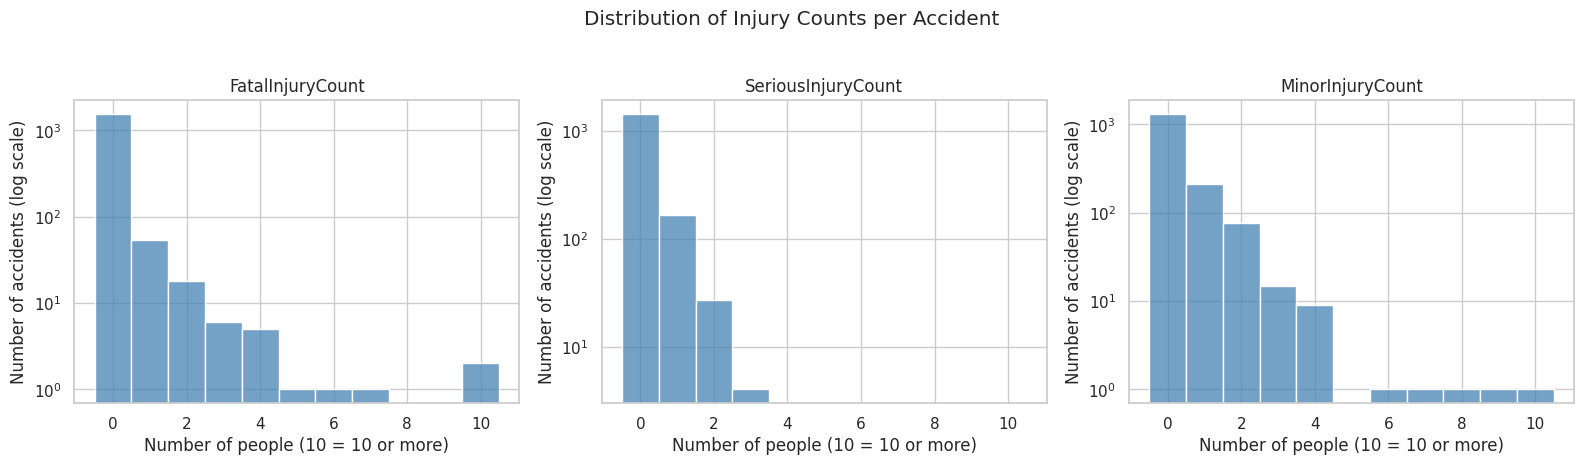

FatalInjuryCount      94.59
SeriousInjuryCount    87.82
MinorInjuryCount      80.57
Name: % of accidents with zero, dtype: float64


In [280]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

# Year extracted from the already-converted EventDate
eda_df["Year"] = eda_df["EventDate"].dt.year

# Histograms of injury counts (log y-axis because most accidents have 0)
injury_cols = ["FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, injury_cols):
    capped = eda_df[col].clip(upper=10)          # 10 means "10 or more"
    sns.histplot(capped, bins=np.arange(-0.5, 11.5, 1), color="steelblue", ax=ax)
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("Number of people (10 = 10 or more)")
    ax.set_ylabel("Number of accidents (log scale)")
plt.suptitle("Distribution of Injury Counts per Accident", y=1.03)
plt.tight_layout()
plt.show()

print((eda_df[injury_cols] == 0).mean().mul(100).round(2).rename("% of accidents with zero"))

**Histogram interpretation:** The three panels show the distributions of fatal, serious, and minor injuries per accident. Injury counts are capped **for display only** at 10 or more; the underlying data are not changed. A logarithmic count axis helps make infrequent outcomes visible. The printed percentages summarize zero counts for each injury field.

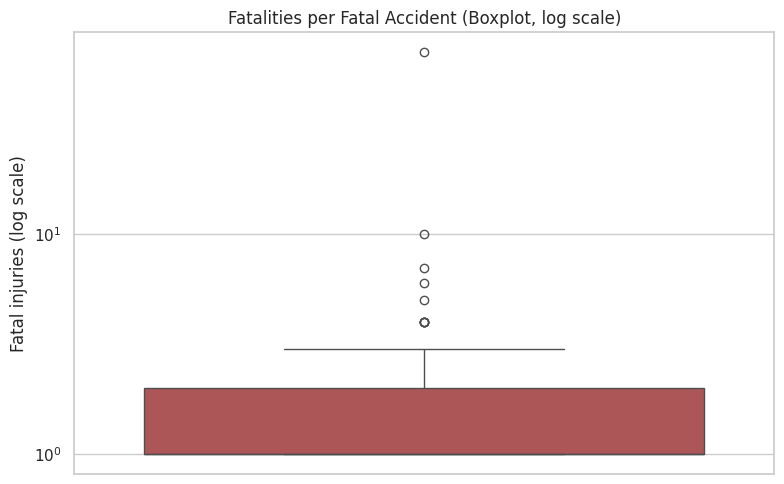

Fatal accidents: 88
Median fatalities: 1.0  |  Upper fence (IQR): 3.5
Outlier accidents above the fence: 10  |  Max: 67


In [281]:
# Boxplot of fatalities among accidents with at least one fatality
fatal_only = eda_df.loc[eda_df["FatalInjuryCount"] > 0, "FatalInjuryCount"]

plt.figure(figsize=(8, 5))
sns.boxplot(y=fatal_only, color="#BC4749")
plt.yscale("log")
plt.title("Fatalities per Fatal Accident (Boxplot, log scale)")
plt.ylabel("Fatal injuries (log scale)")
plt.tight_layout()
plt.show()

# IQR-based outlier summary
q1, q3 = fatal_only.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
outliers = fatal_only[fatal_only > upper_fence]
print(f"Fatal accidents: {len(fatal_only)}")
print(f"Median fatalities: {fatal_only.median()}  |  Upper fence (IQR): {upper_fence}")
print(f"Outlier accidents above the fence: {len(outliers)}  |  Max: {fatal_only.max()}")

**Boxplot interpretation:** This plot focuses on accidents with at least one recorded fatality. The logarithmic scale helps display unusually large fatality counts, and the IQR summary identifies observations worth reviewing—not automatic errors or records to delete.

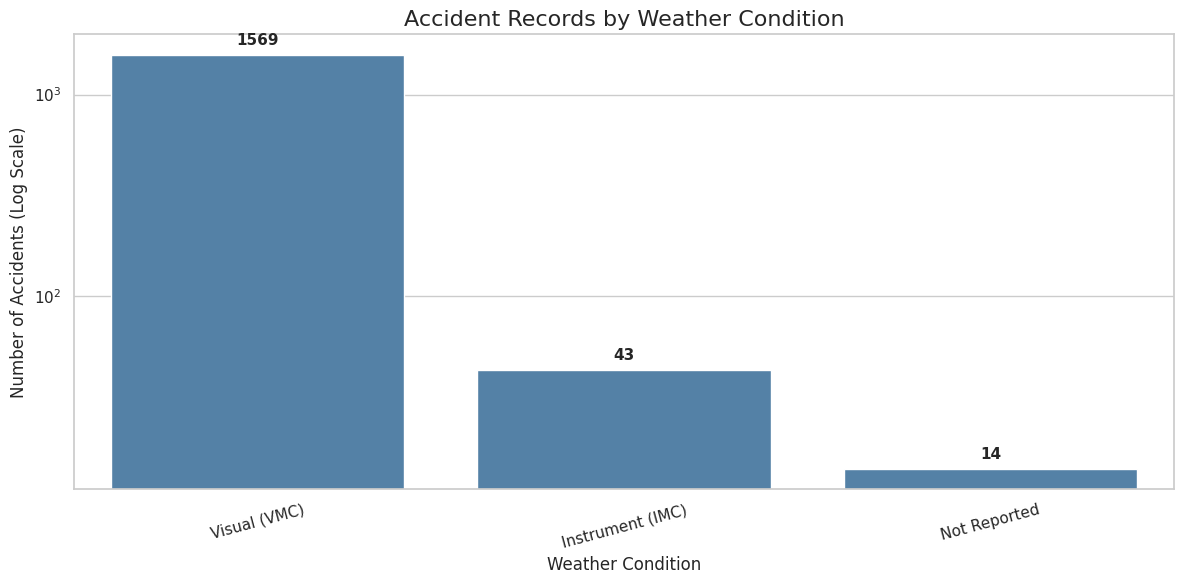

In [282]:

plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=eda_df,
    x="WeatherCondition",
    order=eda_df["WeatherCondition"].value_counts().index,
    color="steelblue"
)

ax.set_yscale("log")


for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=11,
        fontweight="bold"
    )

plt.title("Accident Records by Weather Condition", fontsize=16)
plt.xlabel("Weather Condition", fontsize=12)
plt.ylabel("Number of Accidents (Log Scale)", fontsize=12)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


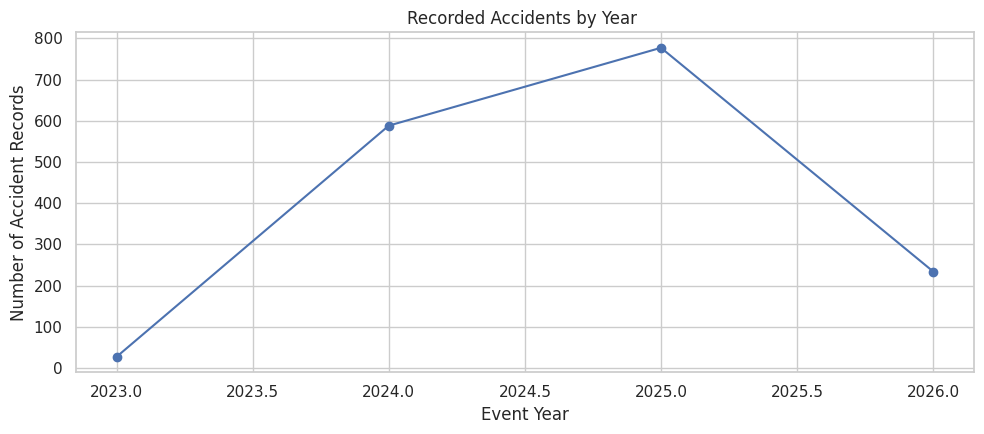

Year coverage: 2023 to 2026


In [283]:
# Recorded accidents by event year
eda_df["EventYear"] = pd.to_datetime(eda_df["EventDate"], errors="coerce").dt.year
yearly_counts = eda_df["EventYear"].value_counts().sort_index()
plt.figure(figsize=(10, 4.5))
plt.plot(yearly_counts.index, yearly_counts.values, marker="o")
plt.title("Recorded Accidents by Year ")
plt.xlabel("Event Year")
plt.ylabel("Number of Accident Records")
plt.tight_layout()
plt.show()
print("Year coverage:", yearly_counts.index.min(), "to", yearly_counts.index.max())

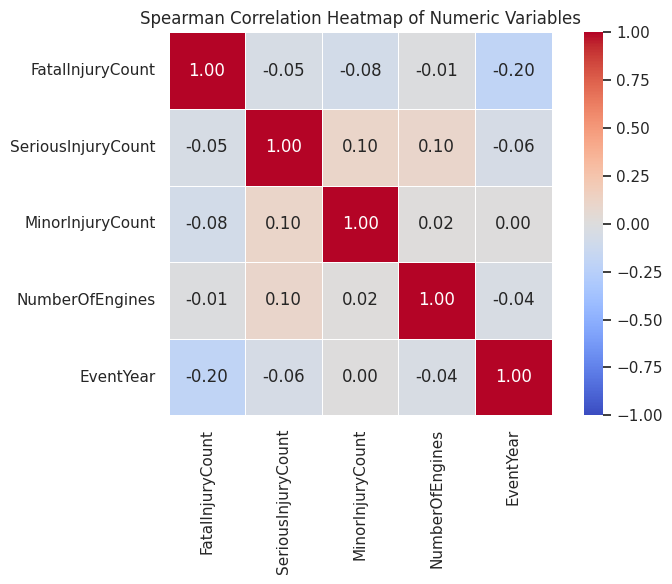

In [284]:
num_cols = ["FatalInjuryCount", "SeriousInjuryCount", "MinorInjuryCount",
            "NumberOfEngines", "EventYear"]

# Spearman is used because the injury counts are strongly skewed
corr = eda_df[num_cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Spearman Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

**Correlation interpretation:** Spearman rank correlations describe monotonic associations between selected numeric fields. They are more suitable for these strongly skewed counts than a standard Pearson-only view, but correlation cannot establish causality. Missing pairs are omitted by Pandas.

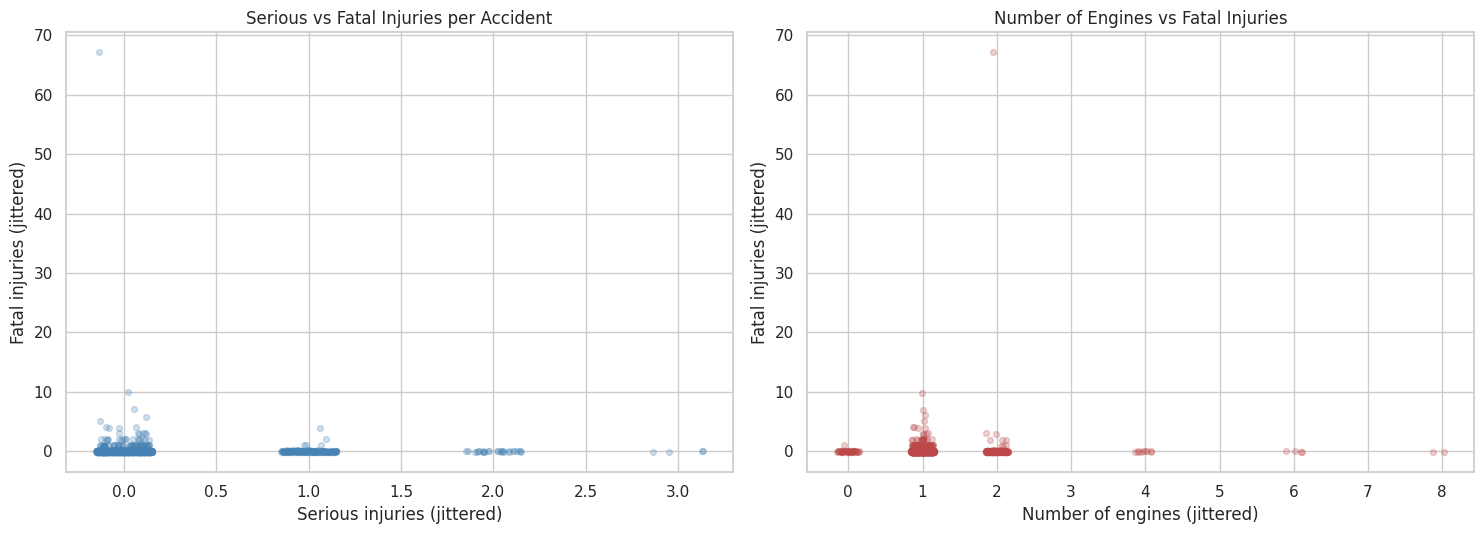

In [285]:
import numpy as np
rng = np.random.default_rng(42)
def jitter(s, amount=0.15):
    return s + rng.uniform(-amount, amount, len(s))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Serious vs Fatal injuries
axes[0].scatter(jitter(eda_df["SeriousInjuryCount"]), jitter(eda_df["FatalInjuryCount"]),
                alpha=0.25, s=18, color="steelblue")
axes[0].set_title("Serious vs Fatal Injuries per Accident")
axes[0].set_xlabel("Serious injuries (jittered)")
axes[0].set_ylabel("Fatal injuries (jittered)")

# Number of engines vs Fatal injuries
eng = eda_df.dropna(subset=["NumberOfEngines"])
axes[1].scatter(jitter(eng["NumberOfEngines"]), jitter(eng["FatalInjuryCount"]),
                alpha=0.25, s=18, color="#BC4749")
axes[1].set_title("Number of Engines vs Fatal Injuries")
axes[1].set_xlabel("Number of engines (jittered)")
axes[1].set_ylabel("Fatal injuries (jittered)")

plt.tight_layout()
plt.show()

**Scatter interpretation:** Small reproducible horizontal and vertical jitter makes overlapping integer-count observations easier to see, including serious injuries versus fatalities and engine counts versus fatalities. Jitter is **visual only**, not a change to accident records. Neither plot establishes a causal relationship.


## 5. Exploratory Data Analysis (EDA)

### 5.1 CASE 01 — The Deadliest Moment

This analysis examines the distribution of aviation accidents across reported flight phases and investigates whether the most frequently reported phase also has the highest proportion of fatal accidents.


In [286]:

# Count accidents by flight phase

phase_counts = eda_df["BroadPhaseofFlight"].value_counts(dropna=False)

display(phase_counts)


,count
BroadPhaseofFlight,
Landing,603
Takeoff,152
Enroute,106
Maneuvering,99
Approach,86
...,...
Taxi; Takeoff,1
Enroute; Approach; EmergencyDescent; Landing,1
Landing; Approach; Takeoff,1



### Flight Phase Preparation

Some accident records contain multiple reported flight phases separated by semicolons. These values are separated into individual phases to support clearer analysis while preserving the original accident records.


In [287]:
# Create a separate dataset for flight-phase analysis
phase_df = eda_df.copy()

# Split multiple flight phases
phase_df["BroadPhaseofFlight"] = (
    phase_df["BroadPhaseofFlight"].str.split(";")
)

# Convert each phase into a separate row
phase_df = phase_df.explode("BroadPhaseofFlight")

# Remove extra spaces
phase_df["BroadPhaseofFlight"] = (
    phase_df["BroadPhaseofFlight"].str.strip()
)

# Remove duplicate phases within the same accident
phase_df = phase_df.drop_duplicates(
    subset=["NtsbNo", "BroadPhaseofFlight"]
)

# Count accidents associated with each phase
phase_counts = phase_df["BroadPhaseofFlight"].value_counts()

display(phase_counts)


,count
BroadPhaseofFlight,
Landing,876
Enroute,239
Takeoff,207
Approach,207
Maneuvering,147
EmergencyDescent,124
InitialClimb,120
Standing,91
Taxi,81


In [288]:
# Exclude unknown flight phases
phase_plot_df = phase_df[
    phase_df["BroadPhaseofFlight"].notna()
    & ~phase_df["BroadPhaseofFlight"].isin(
        ["Unknown", "Not Reported", ""]
    )
].copy()

# Count accidents in each flight phase
phase_counts = (
    phase_plot_df["BroadPhaseofFlight"]
    .value_counts()
    .sort_values(ascending=True)
)

display(phase_counts)


,count
BroadPhaseofFlight,
UncontrolledDescent,47
Post-Impact,47
Taxi,81
Standing,91
InitialClimb,120
EmergencyDescent,124
Maneuvering,147
Approach,207
Takeoff,207


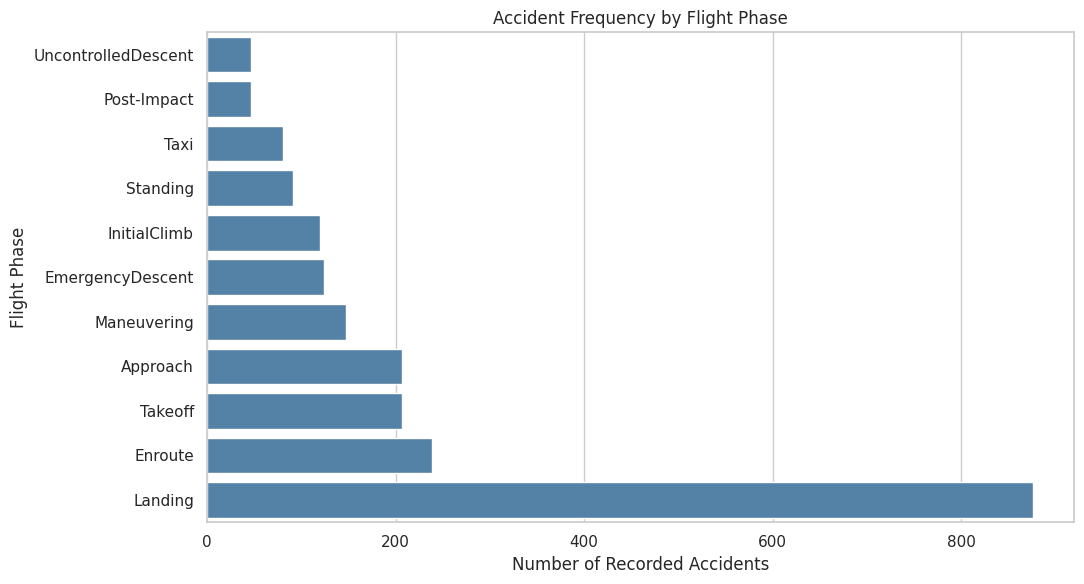

In [289]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    x=phase_counts.values,
    y=phase_counts.index,
    color="steelblue"
)

plt.title("Accident Frequency by Flight Phase")
plt.xlabel("Number of Recorded Accidents")
plt.ylabel("Flight Phase")

plt.tight_layout()
plt.show()


In [290]:

# Create fatal accident indicator
phase_plot_df["FatalAccident"] = (
    phase_plot_df["FatalInjuryCount"] > 0
)

# Calculate fatal accident proportion by phase
phase_fatal = phase_plot_df.groupby(
    "BroadPhaseofFlight"
).agg(
    TotalAccidents=("NtsbNo", "nunique"),
    FatalAccidents=("FatalAccident", "sum")
)

phase_fatal["FatalPercentage"] = (
    phase_fatal["FatalAccidents"]
    / phase_fatal["TotalAccidents"] * 100
).round(2)

phase_fatal = phase_fatal.sort_values(
    "FatalPercentage", ascending=False
)

display(phase_fatal)


,TotalAccidents,FatalAccidents,FatalPercentage
BroadPhaseofFlight,,,
UncontrolledDescent,47,23,48.94
Maneuvering,147,27,18.37
Enroute,239,27,11.30
Post-Impact,47,5,10.64
InitialClimb,120,12,10.00
EmergencyDescent,124,7,5.65
Approach,207,11,5.31
Takeoff,207,10,4.83
Standing,91,1,1.10


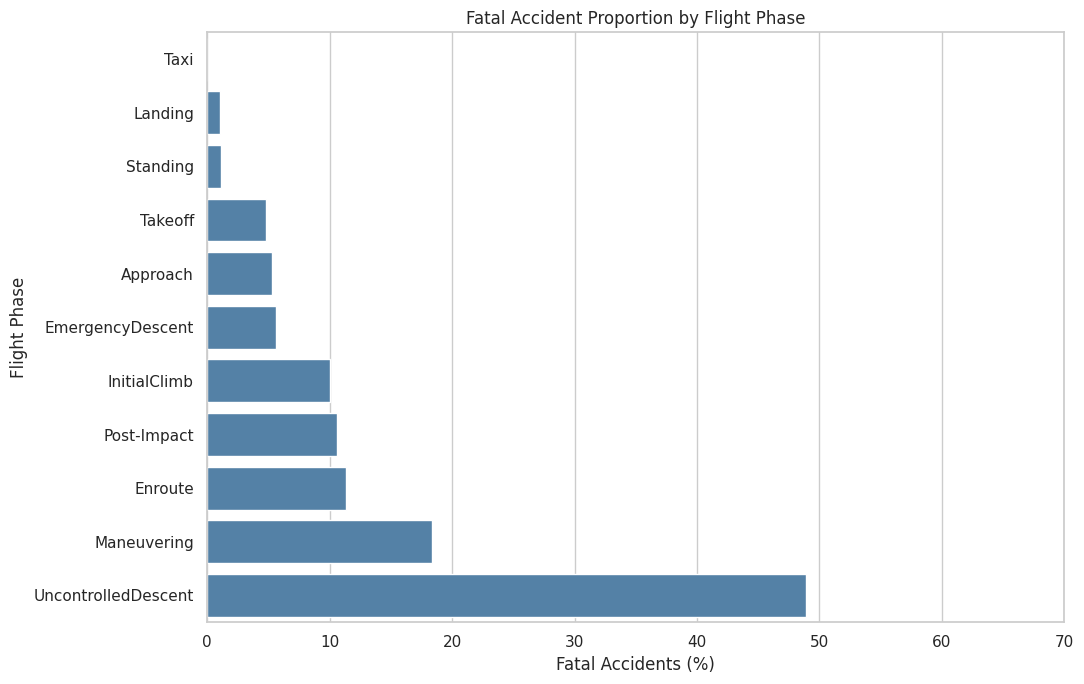

In [291]:

# Exclude phases with fewer than 30 accidents
phase_fatal_plot = phase_fatal[
    phase_fatal["TotalAccidents"] >= 30
].sort_values("FatalPercentage", ascending=True)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=phase_fatal_plot.reset_index(),
    x="FatalPercentage",
    y="BroadPhaseofFlight",
    color="steelblue"
)

plt.title("Fatal Accident Proportion by Flight Phase")
plt.xlabel("Fatal Accidents (%)")
plt.ylabel("Flight Phase")
plt.xlim(0, 70)

plt.tight_layout()
plt.show()


**Interpretation — CASE 01: The Deadliest Moment**

Landing was the most frequently reported flight phase, associated with 3,139 accidents. However, only 2.20% of these accidents recorded at least one fatality.

In contrast, Uncontrolled Descent had the highest fatal accident proportion (59.82%), with 198 fatal accidents among 331 recorded accidents.

These findings demonstrate that the most frequently reported flight phase is not necessarily associated with the highest proportion of fatal accidents.

Because some accidents were associated with multiple flight phases, the results describe phase-specific associations rather than independent or causal risks.


### 5.2 CASE 02 — The Weather Paradox

This analysis explores whether accidents recorded under Visual Meteorological Conditions (VMC) are associated with less severe outcomes than accidents under Instrument Meteorological Conditions (IMC).

The analysis compares accident frequency, fatal accident proportions, and recorded injury severity across weather conditions.


In [292]:

# Explore weather condition categories

weather_counts = eda_df["WeatherCondition"].value_counts(dropna=False)

display(weather_counts)


,count
WeatherCondition,
Visual (VMC),1569
Instrument (IMC),43
Not Reported,14


In [293]:

# Keep only VMC and IMC accidents
weather_df = eda_df[
    eda_df["WeatherCondition"].isin([
        "Visual (VMC)",
        "Instrument (IMC)"
    ])
].copy()

# Identify fatal accidents
weather_df["FatalAccident"] = (
    weather_df["FatalInjuryCount"] > 0
)

# Calculate fatal accident proportions
weather_fatal = weather_df.groupby(
    "WeatherCondition"
).agg(
    TotalAccidents=("NtsbNo", "nunique"),
    FatalAccidents=("FatalAccident", "sum")
)

weather_fatal["FatalPercentage"] = (
    weather_fatal["FatalAccidents"]
    / weather_fatal["TotalAccidents"] * 100
).round(2)

display(weather_fatal)


,TotalAccidents,FatalAccidents,FatalPercentage
WeatherCondition,,,
Instrument (IMC),43,13,30.23
Visual (VMC),1569,73,4.65


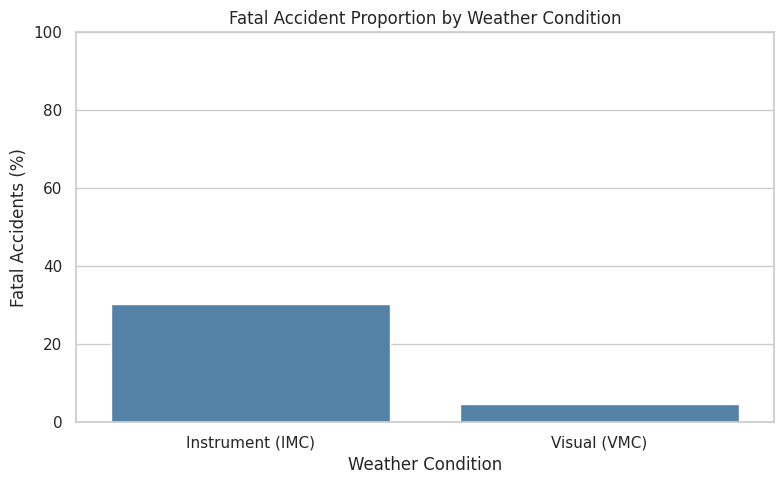

In [294]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=weather_fatal.reset_index(),
    x="WeatherCondition",
    y="FatalPercentage",
    color="steelblue"
)

plt.title("Fatal Accident Proportion by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Fatal Accidents (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()



**Interpretation:**

This visualization compares the proportion of fatal accidents recorded under Visual Meteorological Conditions (VMC) and Instrument Meteorological Conditions (IMC).

The comparison uses the total number of recorded accidents within each weather category as the denominator. Therefore, it describes fatal outcomes among recorded accidents rather than the overall risk of an aviation accident.


In [295]:

# Explore injury severity categories

weather_df["HighestInjuryLevel"].value_counts(dropna=False)


,count
HighestInjuryLevel,
Not Reported,1092
Minor,250
Serious,184
Fatal,86


In [296]:

# Compare injury severity across weather conditions

severity_table = pd.crosstab(
    weather_df["WeatherCondition"],
    weather_df["HighestInjuryLevel"]
)

display(severity_table)


HighestInjuryLevel,Fatal,Minor,Not Reported,Serious
WeatherCondition,,,,
Instrument (IMC),13,2,18,10
Visual (VMC),73,248,1074,174


In [297]:

# Keep accidents with documented injury severity
severity_df = weather_df[
    weather_df["HighestInjuryLevel"].isin(
        ["Fatal", "Serious", "Minor"]
    )
].copy()

# Calculate percentages among documented severity records
severity_percent_valid = pd.crosstab(
    severity_df["WeatherCondition"],
    severity_df["HighestInjuryLevel"],
    normalize="index"
) * 100

display(severity_percent_valid.round(2))

print("Excluded from severity comparison:",
      len(weather_df) - len(severity_df))


HighestInjuryLevel,Fatal,Minor,Serious
WeatherCondition,,,
Instrument (IMC),52.00,8.0,40.00
Visual (VMC),14.75,50.1,35.15


Excluded from severity comparison: 1092


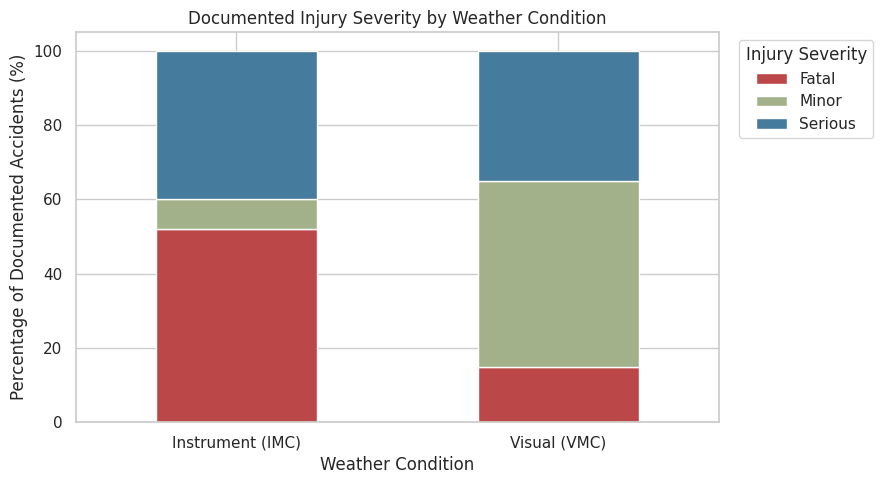

In [298]:

severity_percent_valid.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=[{"Fatal":"#BC4749", "Minor":"#A3B18A", "Serious":"#457B9D"}[x] for x in severity_percent_valid.columns]
)

plt.title("Documented Injury Severity by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Percentage of Documented Accidents (%)")
plt.xticks(rotation=0)

plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


**CASE 02 — The Weather Paradox: Key Findings**

Accidents recorded under Instrument Meteorological Conditions (IMC) showed a substantially higher proportion of fatal injury classifications (59.66%) compared with accidents recorded under Visual Meteorological Conditions (VMC) (11.98%).

Although VMC accounted for considerably more recorded accidents, IMC accidents were more frequently associated with fatal classifications.

However, injury severity was not reported for 20.60% of IMC accidents and 59.91% of VMC accidents. Therefore, these comparisons should be interpreted cautiously, as missing severity information may affect the observed differences.

The findings describe recorded accident outcomes rather than accident risk or a causal effect of weather conditions.

**Denominator clarification:** The `FatalPercentage` plot based on `FatalInjuryCount > 0` uses **all VMC/IMC accidents** in the selected data; the documented-severity stacked plot uses **only records classified as Fatal, Serious, or Minor**. The percentages differ because the denominator differs, and they must not be interchanged.


In [299]:

# Compare recorded fatalities with injury classification

severity_check = pd.crosstab(
    eda_df["HighestInjuryLevel"],
    eda_df["FatalInjuryCount"] > 0
)

display(severity_check)


FatalInjuryCount,False,True
HighestInjuryLevel,,
Fatal,0,88
Minor,251,0
Not Reported,1094,0
Serious,193,0



### 5.3 CASE 03 — Human Error or Mechanical Failure?

**Research Question:**

Which contributing-factor categories appear most frequently in official investigation findings?

**Objective:**

To analyze documented aviation accident findings and identify the most frequently reported contributing-factor categories, including human, mechanical, and environmental factors.

**Approach:**

The analysis focuses on available investigation findings. Missing findings are excluded, and accidents may involve more than one contributing factor.


In [300]:

# Explore investigation findings

print("Total accidents:", len(eda_df))

print("Available findings:",
      eda_df["Findings"].notna().sum())

display(eda_df["Findings"].dropna().head(10))


Total accidents: 1626
Available findings: 1626


,Findings
4,Aircraft - Aircraft systems - Fuel system - In...
5,Personnel issues - Task performance - Use of e...
12,Environmental issues - Conditions/weather/phen...
14,Personnel issues - Psychological - Attention/m...
16,Environmental issues - Conditions/weather/phen...
17,Aircraft - Aircraft systems - Landing gear sys...
19,Personnel issues - Task performance - Use of e...
20,Personnel issues - Task performance - Maintena...
21,Aircraft - Aircraft oper/perf/capability - Per...
22,Personnel issues - Action/decision - Info proc...


In [301]:

# Display complete investigation findings

for finding in eda_df["Findings"].head(5):
    print(finding)
    print("-" * 60)


Aircraft - Aircraft systems - Fuel system - Incorrect use/operation; Personnel issues - Task performance - Use of equip/info - Pilot; Aircraft - Aircraft systems - Fuel system - Damaged/degraded
------------------------------------------------------------
Personnel issues - Task performance - Use of equip/info - Pilot; Personnel issues - Action/decision - Action - Pilot; Aircraft - Aircraft systems - Landing gear system - Not used/operated; Aircraft - Aircraft systems - Landing gear system - Not used/operated; Personnel issues - Action/decision - Action - Pilot; Personnel issues - Psychological - Attention/monitoring - Pilot
------------------------------------------------------------
Environmental issues - Conditions/weather/phenomena - Wind - Effect on equipment; Personnel issues - Task performance - Use of equip/info - Student/instructed pilot; Environmental issues - Conditions/weather/phenomena - Wind - Ability to respond/compensate
-------------------------------------------------

In [302]:

# Create a separate dataset for findings analysis
factor_df = eda_df[["NtsbNo", "Findings"]].copy()

# Split findings into individual rows
factor_df["Findings"] = factor_df["Findings"].str.split(";")

factor_df = factor_df.explode("Findings")

# Remove extra spaces
factor_df["Findings"] = factor_df["Findings"].str.strip()

# Extract original main category
factor_df["MainCategory"] = (
    factor_df["Findings"]
    .str.split(" - ")
    .str[0]
    .str.strip()
)

display(factor_df["MainCategory"].value_counts())


,count
MainCategory,
Personnel issues,2034
Aircraft,1679
Environmental issues,858
Organizational issues,58
Not determined,40



#### Investigation Factor Categories

The investigation findings were grouped into five categories based on their original classification: Human Factors, Aircraft-Related Factors, Environmental Factors, Organizational Factors, and Undetermined Factors.

Each accident was counted only once within each category, even if multiple findings from the same category were reported.


In [303]:

# Map original findings to analytical categories

category_map = {
    "Personnel issues": "Human Factors",
    "Aircraft": "Aircraft-Related Factors",
    "Environmental issues": "Environmental Factors",
    "Organizational issues": "Organizational Factors",
    "Not determined": "Undetermined"
}

factor_df["FactorCategory"] = (
    factor_df["MainCategory"].map(category_map)
)

# Check any unmapped categories
display(
    factor_df.loc[
        factor_df["FactorCategory"].isna(),
        "MainCategory"
    ].value_counts()
)

# Count each accident once per factor category
factor_unique = factor_df.dropna(
    subset=["FactorCategory"]
).drop_duplicates(
    subset=["NtsbNo", "FactorCategory"]
)

factor_counts = (
    factor_unique["FactorCategory"]
    .value_counts()
)

display(factor_counts)


,count
MainCategory,


,count
FactorCategory,
Human Factors,1318
Aircraft-Related Factors,1301
Environmental Factors,637
Undetermined,39
Organizational Factors,27


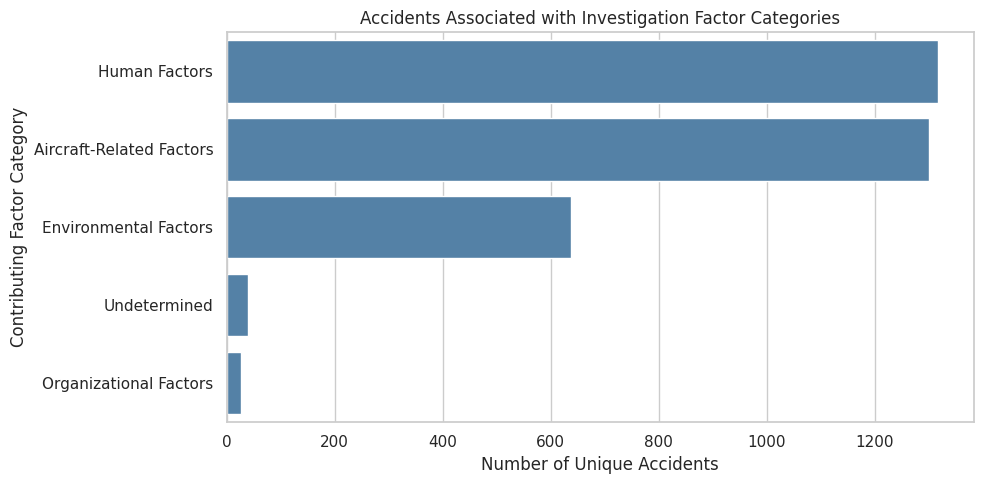

In [304]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=factor_counts.values,
    y=factor_counts.index,
    color="steelblue"
)

plt.title("Accidents Associated with Investigation Factor Categories")
plt.xlabel("Number of Unique Accidents")
plt.ylabel("Contributing Factor Category")

plt.tight_layout()
plt.show()



**Interpretation — CASE 03: Human Error or Mechanical Failure?**

Aircraft-related factors were the most frequently documented category, appearing in 5,361 accidents, followed closely by human factors in 5,248 accidents. Environmental factors appeared in 2,458 accidents, while undetermined and organizational factors were less frequent.

The small difference between aircraft-related and human factors indicates that both categories are prominent in the investigation findings.

However, aircraft-related findings do not necessarily indicate mechanical failure, and multiple factor categories may be associated with the same accident. Therefore, these results describe documented investigation associations rather than exclusive accident causes.


*Terminology note:* Aircraft-related investigation findings include systems, performance, and operation; they should not be interpreted as exclusively mechanical failures.



### 5.4 CASE 04 — Does the Aircraft Matter?

**Research Question:**

How do recorded fatal-outcome proportions differ across aircraft categories and engine configurations?

**Objective:**

To investigate differences in fatal accident proportions across aircraft categories, engine types, and the number of engines.

**Approach:**

Fatal accident proportions will be calculated within each aircraft or engine category. Missing engine-count values will be excluded only from the relevant comparison.


In [305]:
print("Aircraft Categories:")
display(eda_df["AirCraftCategory"].value_counts(dropna=False))

print("\nEngine Types:")
display(eda_df["EngineType"].value_counts(dropna=False))

print("\nNumber of Engines:")
display(
    eda_df["NumberOfEngines"]
    .value_counts(dropna=False)
    .sort_index()
)


Aircraft Categories:


,count
AirCraftCategory,
Airplane,1399
Helicopter,143
Glider,34
Balloon,19
Gyroplane,16
Weight-shift,4
Powered parachute,3
Helicopter; Unknown,2
Unknown,2



Engine Types:


,count
EngineType,
Reciprocating,1209
Reciprocating; Reciprocating,102
Turbo fan; Turbo fan,77
Turbo shaft,72
Turbo prop,58
Not Reported,48
Turbo prop; Turbo prop,22
Turbo fan; Turbo fan; Turbo fan; Turbo fan,7
Turbo shaft; Turbo shaft,5



Number of Engines:


,count
NumberOfEngines,
0.0,45
1.0,1365
2.0,199
4.0,9
6.0,4
8.0,2
NaN,2


In [306]:

# Create a separate dataset for aircraft categories
aircraft_df = eda_df.copy()

# Split multiple aircraft categories
aircraft_df["AirCraftCategory"] = (
    aircraft_df["AirCraftCategory"].str.split(";")
)

# Convert each category into a separate row
aircraft_df = aircraft_df.explode("AirCraftCategory")


aircraft_df["AirCraftCategory"] = (
    aircraft_df["AirCraftCategory"].str.strip()
)


aircraft_df = aircraft_df.drop_duplicates(
    subset=["NtsbNo", "AirCraftCategory"]
)


aircraft_df = aircraft_df[
    ~aircraft_df["AirCraftCategory"].isin(
        ["Unknown", "Not Reported", ""]
    )
].copy()

display(aircraft_df["AirCraftCategory"].value_counts())


,count
AirCraftCategory,
Airplane,1401
Helicopter,146
Glider,34
Balloon,19
Gyroplane,16
Weight-shift,4
Powered parachute,3
Powered-lift,1
Ultralight,1


In [307]:

# Calculate fatal accident proportions by aircraft category

aircraft_df["FatalAccident"] = (
    aircraft_df["FatalInjuryCount"] > 0
)

aircraft_fatal = aircraft_df.groupby(
    "AirCraftCategory"
).agg(
    TotalAccidents=("NtsbNo", "nunique"),
    FatalAccidents=("FatalAccident", "sum")
)

aircraft_fatal["FatalPercentage"] = (
    aircraft_fatal["FatalAccidents"]
    / aircraft_fatal["TotalAccidents"] * 100
).round(2)

aircraft_fatal = aircraft_fatal.sort_values(
    "FatalPercentage", ascending=False
)

display(aircraft_fatal)


,TotalAccidents,FatalAccidents,FatalPercentage
AirCraftCategory,,,
Weight-shift,4,2,50.00
Powered parachute,3,1,33.33
Gyroplane,16,2,12.50
Helicopter,146,12,8.22
Glider,34,2,5.88
Balloon,19,1,5.26
Airplane,1401,69,4.93
Powered-lift,1,0,0.00
Ultralight,1,0,0.00


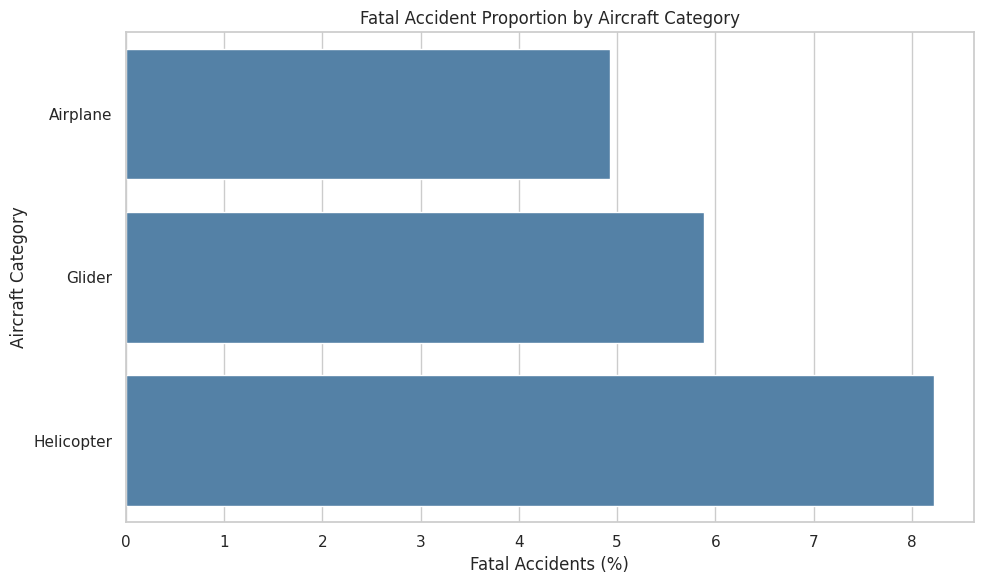

In [308]:

# Keep categories with at least 30 accidents
aircraft_plot = aircraft_fatal[
    aircraft_fatal["TotalAccidents"] >= 30
].sort_values("FatalPercentage", ascending=True)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=aircraft_plot.reset_index(),
    x="FatalPercentage",
    y="AirCraftCategory",
    color="steelblue"
)

plt.title("Fatal Accident Proportion by Aircraft Category")
plt.xlabel("Fatal Accidents (%)")
plt.ylabel("Aircraft Category")

plt.tight_layout()
plt.show()


#### Engine Type and Engine Count Comparisons

Engine-type entries may list multiple engines in one accident, including repeated types. We count each accident at most once per **engine type**. An accident may be associated with more than one type. Missing or unknown engine-type labels are excluded from the comparison, not from the main dataset. For engine counts, only records with a documented count are used; zero-engine aircraft are retained as a separate category because they can represent valid aircraft. These comparisons describe accident outcomes, **not** the safety benefit of a particular engine configuration.


In [309]:
# Engine types: one accident can have several engine-type labels
engine_type_df = eda_df[["NtsbNo", "EngineType", "FatalInjuryCount"]].copy()
engine_type_df["EngineType"] = engine_type_df["EngineType"].str.split(";")
engine_type_df = engine_type_df.explode("EngineType")
engine_type_df["EngineType"] = engine_type_df["EngineType"].str.strip()
engine_type_df = engine_type_df[
    engine_type_df["EngineType"].notna()
    & ~engine_type_df["EngineType"].isin(["", "Unknown", "Not Reported"])
].drop_duplicates(subset=["NtsbNo", "EngineType"]).copy()
engine_type_df["FatalAccident"] = engine_type_df["FatalInjuryCount"] > 0
engine_type_summary = engine_type_df.groupby("EngineType").agg(
    TotalAccidents=("NtsbNo", "nunique"),
    FatalAccidents=("FatalAccident", "sum")
)
engine_type_summary["FatalPercentage"] = (
    100 * engine_type_summary["FatalAccidents"] / engine_type_summary["TotalAccidents"]
).round(2)
display(engine_type_summary.sort_values("TotalAccidents", ascending=False))


,TotalAccidents,FatalAccidents,FatalPercentage
EngineType,,,
Reciprocating,1312,66,5.03
Turbo fan,90,3,3.33
Turbo prop,82,8,9.76
Turbo shaft,78,10,12.82
Electric,12,0,0.00
Turbo jet,8,0,0.00


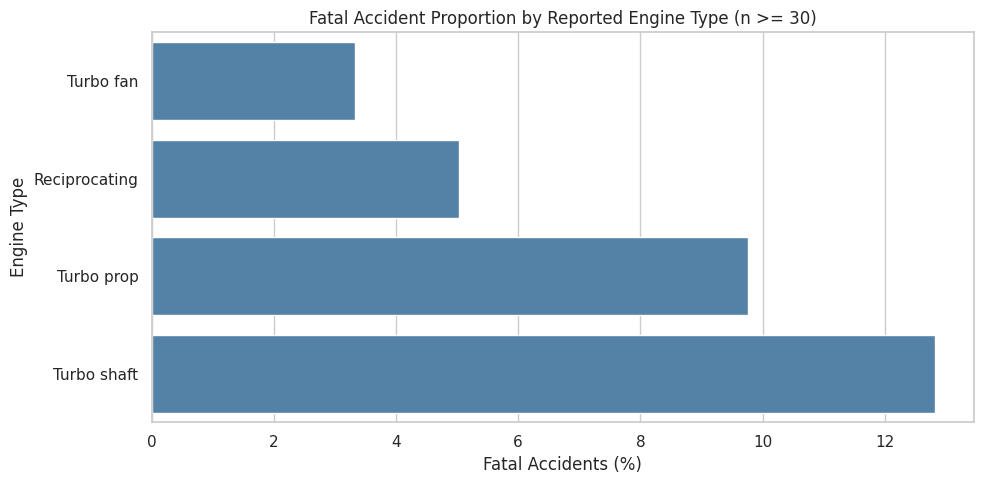

In [310]:
# Display types with at least 30 recorded accidents
engine_type_plot = engine_type_summary[
    engine_type_summary["TotalAccidents"] >= 30
].sort_values("FatalPercentage")
plt.figure(figsize=(10, 5))
sns.barplot(x=engine_type_plot["FatalPercentage"], y=engine_type_plot.index,
            color="steelblue")
plt.title("Fatal Accident Proportion by Reported Engine Type (n >= 30)")
plt.xlabel("Fatal Accidents (%)")
plt.ylabel("Engine Type")
plt.tight_layout()
plt.show()


In [311]:
# Number of engines: do not impute missing counts
engine_count_df = eda_df.dropna(subset=["NumberOfEngines"]).copy()
engine_count_df["FatalAccident"] = engine_count_df["FatalInjuryCount"] > 0
engine_count_summary = engine_count_df.groupby("NumberOfEngines").agg(
    TotalAccidents=("NtsbNo", "nunique"),
    FatalAccidents=("FatalAccident", "sum")
)
engine_count_summary["FatalPercentage"] = (
    100 * engine_count_summary["FatalAccidents"] / engine_count_summary["TotalAccidents"]
).round(2)
print("Excluded missing engine counts:", eda_df["NumberOfEngines"].isna().sum())
display(engine_count_summary.sort_index())


Excluded missing engine counts: 2


,TotalAccidents,FatalAccidents,FatalPercentage
NumberOfEngines,,,
0.0,45,1,2.22
1.0,1365,77,5.64
2.0,199,9,4.52
4.0,9,0,0.00
6.0,4,0,0.00
8.0,2,0,0.00


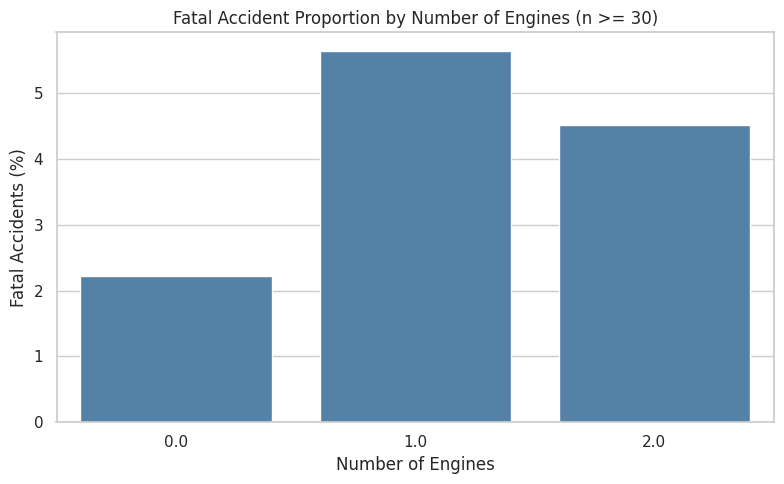

In [312]:
# Limit visual comparison to engine-count groups with at least 30 accidents
engine_count_plot = engine_count_summary[
    engine_count_summary["TotalAccidents"] >= 30
].reset_index()
plt.figure(figsize=(8, 5))
sns.barplot(data=engine_count_plot, x="NumberOfEngines", y="FatalPercentage", color="steelblue", order=sorted(engine_count_plot["NumberOfEngines"].unique()))
plt.title("Fatal Accident Proportion by Number of Engines (n >= 30)")
plt.xlabel("Number of Engines")
plt.ylabel("Fatal Accidents (%)")
plt.tight_layout()
plt.show()


**Interpretation note — CASE 04:** Interpret the engine-type and engine-count results using the calculated percentages and sample sizes above. Do not treat small groups as equally stable, or infer that engine count alone causes better or worse outcomes. Aircraft category, operating environment, and accident characteristics can differ between groups.


The engine-type and engine-count comparison tables above provide the actual subgroup counts and fatal-outcome proportions; interpret them separately from aircraft category results.



### 5.5 CASE 05 — The Survival Paradox

**Research Question:**

Can an aircraft sustain substantial or destructive damage while recording zero fatalities?

**Objective:**

To investigate whether severe aircraft damage is always associated with fatal outcomes, or whether accidents involving substantial or destructive damage can occur without recorded fatalities.

**Approach:**

The analysis compares aircraft damage classifications with recorded fatality counts to identify and quantify accidents involving severe damage but zero recorded fatalities.


In [313]:

# Explore aircraft damage categories

damage_counts = eda_df["AirCraftDamage"].value_counts(dropna=False)

display(damage_counts)


,count
AirCraftDamage,
Substantial,1460
Destroyed,75
Not Reported,59
Minor,13
Substantial; Minor,11
Minor; Substantial,4
Destroyed; Substantial,1
Minor; Destroyed,1
Substantial; Unknown,1



#### Aircraft Damage Preparation

Some accident records contain multiple aircraft damage classifications. These classifications were separated to identify accidents associated with substantial or destroyed aircraft.

Each accident is counted once within each damage category.


In [314]:

# Create a separate dataset for aircraft damage
damage_df = eda_df.copy()

# Split multiple damage categories
damage_df["AirCraftDamage"] = (
    damage_df["AirCraftDamage"].str.split(";")
)

# Convert each damage category into a separate row
damage_df = damage_df.explode("AirCraftDamage")

# Remove extra spaces
damage_df["AirCraftDamage"] = (
    damage_df["AirCraftDamage"].str.strip()
)

# Remove repeated damage categories within the same accident
damage_df = damage_df.drop_duplicates(
    subset=["NtsbNo", "AirCraftDamage"]
)

# Keep known damage categories
damage_df = damage_df[
    damage_df["AirCraftDamage"].isin(
        ["Destroyed", "Substantial", "Minor", "None"]
    )
].copy()

display(damage_df["AirCraftDamage"].value_counts())


,count
AirCraftDamage,
Substantial,1478
Destroyed,78
Minor,29


In [315]:

# Select accidents with severe aircraft damage
severe_damage_df = damage_df[
    damage_df["AirCraftDamage"].isin(
        ["Destroyed", "Substantial"]
    )
].copy()

# Identify accidents with zero recorded fatalities
severe_damage_df["ZeroFatalities"] = (
    severe_damage_df["FatalInjuryCount"] == 0
)

# Summarize results
survival_summary = severe_damage_df.groupby(
    "AirCraftDamage"
).agg(
    TotalAccidents=("NtsbNo", "nunique"),
    ZeroFatalAccidents=("ZeroFatalities", "sum")
)

survival_summary["ZeroFatalPercentage"] = (
    survival_summary["ZeroFatalAccidents"]
    / survival_summary["TotalAccidents"] * 100
).round(2)

display(survival_summary)


,TotalAccidents,ZeroFatalAccidents,ZeroFatalPercentage
AirCraftDamage,,,
Destroyed,78,36,46.15
Substantial,1478,1435,97.09


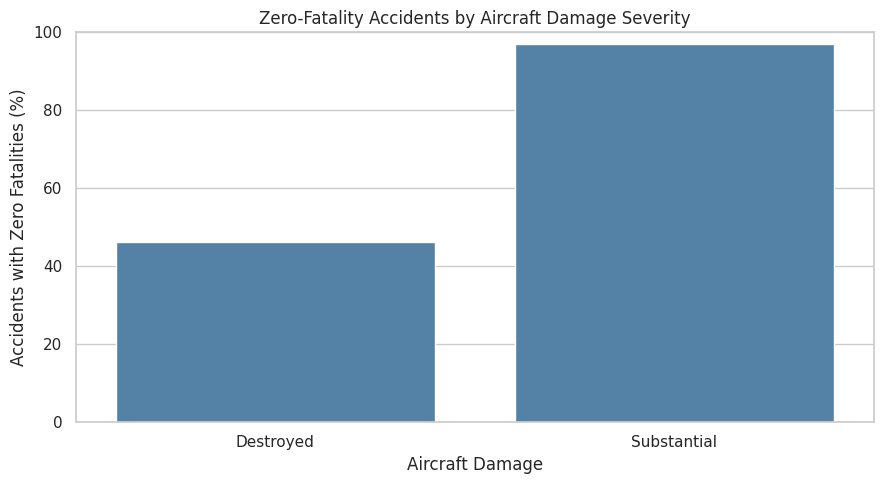

In [316]:

# Visualize zero-fatality accident proportions

damage_plot = survival_summary.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=damage_plot,
    x="AirCraftDamage",
    y="ZeroFatalPercentage",
    color="steelblue"
)

plt.title("Zero-Fatality Accidents by Aircraft Damage Severity")
plt.xlabel("Aircraft Damage")
plt.ylabel("Accidents with Zero Fatalities (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()



**Interpretation — CASE 05: The Survival Paradox**

Among accidents involving substantial aircraft damage, 92.23% (5,416 of 5,872) recorded zero fatalities.

More notably, 22.99% (137 of 596) of accidents involving destroyed aircraft also recorded zero fatalities.

These findings demonstrate that severe aircraft damage does not necessarily result in recorded fatalities.

However, aircraft damage and fatality counts describe different aspects of an accident. The absence of recorded fatalities does not necessarily mean that all occupants were uninjured, and accidents involving multiple aircraft may contribute to more than one damage category.



### 5.6 CASE 06 — The Hidden Pattern

**Research Question:**

How do documented investigation findings differ between fatal and nonfatal aviation accidents?

**Objective:**

To compare the distribution of documented contributing-factor categories between fatal and nonfatal aviation accidents.

**Approach:**

The analysis uses the investigation factor categories identified in CASE 03. Fatal and nonfatal accidents are compared using within-group percentages to account for differences in group sizes.


In [317]:

# Prepare investigation findings for CASE 06

case6_df = factor_unique.copy()

# Add fatal accident status
case6_df["FatalAccident"] = (
    case6_df["FatalInjuryCount"] > 0
    if "FatalInjuryCount" in case6_df.columns
    else case6_df["NtsbNo"].map(
        eda_df.set_index("NtsbNo")["FatalInjuryCount"]
    ) > 0
)

# Check fatal and nonfatal accident counts
display(
    case6_df.groupby("FatalAccident")["NtsbNo"].nunique()
)


,NtsbNo
FatalAccident,
False,1538
True,88


In [318]:

# Count unique accidents by outcome and factor category

case6_counts = pd.crosstab(
    case6_df["FactorCategory"],
    case6_df["FatalAccident"]
)

case6_counts = case6_counts.rename(
    columns={False: "Nonfatal", True: "Fatal"}
)

display(case6_counts)


FatalAccident,Nonfatal,Fatal
FactorCategory,,
Aircraft-Related Factors,1238,63
Environmental Factors,601,36
Human Factors,1247,71
Organizational Factors,20,7
Undetermined,28,11


In [319]:

# Count accidents in each outcome group
outcome_totals = eda_df.groupby(
    eda_df["FatalInjuryCount"] > 0
)["NtsbNo"].nunique()

# Calculate factor prevalence within each group
case6_percent = case6_counts.copy()

case6_percent["Nonfatal"] = (
    case6_counts["Nonfatal"] / outcome_totals[False] * 100
)

case6_percent["Fatal"] = (
    case6_counts["Fatal"] / outcome_totals[True] * 100
)

case6_percent = case6_percent.round(2)

display(case6_percent)


FatalAccident,Nonfatal,Fatal
FactorCategory,,
Aircraft-Related Factors,80.49,71.59
Environmental Factors,39.08,40.91
Human Factors,81.08,80.68
Organizational Factors,1.30,7.95
Undetermined,1.82,12.50


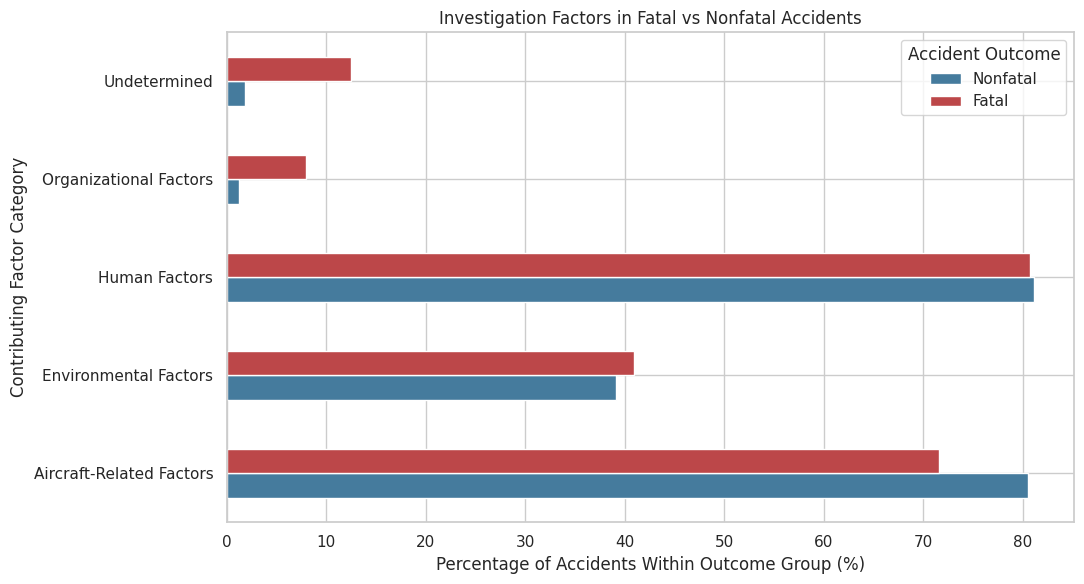

In [320]:

# Compare factor prevalence in fatal and nonfatal accidents

case6_percent.plot(
    kind="barh",
    figsize=(11, 6),
    color=["#457B9D", "#BC4749"]
)

plt.title("Investigation Factors in Fatal vs Nonfatal Accidents")
plt.xlabel("Percentage of Accidents Within Outcome Group (%)")
plt.ylabel("Contributing Factor Category")
plt.legend(title="Accident Outcome")

plt.tight_layout()
plt.show()



**Interpretation — CASE 06: The Hidden Pattern**

Human factors were documented in 85.68% of fatal accidents compared with 77.14% of nonfatal accidents.

Aircraft-related factors were more frequently documented in nonfatal accidents (80.84%) than fatal accidents (74.73%).

Environmental factors showed relatively similar proportions in both groups, while undetermined findings were more common among fatal accidents (10.41% versus 4.50%).

These results reveal differences in documented investigation findings between fatal and nonfatal accidents. However, multiple factors may be reported for the same accident, and these associations do not establish causation.


## 6. Key Findings

Across **6,701 analyzed accident records**, six questions reveal meaningful differences between the frequency of recorded accidents and the severity of their outcomes.

1. **The Deadliest Moment:** Landing appeared in the most accidents (**3,139**), yet only **2.20%** recorded fatalities. Uncontrolled descent showed the highest fatal-accident proportion (**59.82%**, 198 of 331).
2. **The Weather Paradox:** **11.98%** of VMC accidents (768/6,413) were fatal, compared with **59.66%** under IMC (139/233). In the *documented injury-severity subset*, fatal classifications comprised 29.87% for VMC and 75.14% for IMC; these percentages use different denominators.
3. **Human Error or Mechanical Failure?:** Aircraft-related findings appeared in **5,361** accidents and human factors in **5,248**. A single accident may contain multiple finding categories; aircraft-related does not mean mechanical failure alone.
4. **Does the Aircraft Matter?:** Fatal-accident proportions differed by aircraft characteristics. Airplanes accounted for **5,787** accidents (13.53% fatal), while weight-shift aircraft showed **38.46% fatal** among 39 recorded accidents. Engine-type comparisons also varied, with **25.00%** for turbo prop and **5.80%** for turbo fan among their analyzed groups. Such comparisons describe outcomes among accidents, not overall aircraft safety.
5. **The Survival Paradox:** **92.23%** of substantially damaged aircraft accidents (5,416/5,872) and **22.99%** of destroyed-aircraft accidents (137/596) recorded zero fatalities. Zero recorded fatalities does not imply zero injuries.
6. **The Hidden Pattern:** Human factors appeared in **85.68%** of fatal and **77.14%** of nonfatal accidents. Aircraft-related factors appeared in **74.73%** of fatal and **80.84%** of nonfatal accidents.

**Overall:** The most frequently recorded circumstances were not necessarily those with the highest proportions of fatal outcomes. The results are descriptive, not causal.


## 7. Limitations

The findings should be interpreted within the scope of recorded accidents:

1. **Analysis subset:** The core analysis includes **6,701** records with available investigation findings and probable causes, selected from **9,995** cleaned accident records. This defines the population described in the charts.
2. **Reporting and classification:** Some injury-severity classifications are not reported. The weather injury-severity comparison therefore uses only accidents with a documented category; its denominator differs from the main fatal-outcome comparison.
3. **Multi-label records:** An accident can appear in several flight-phase, aircraft-damage, or factor categories. Counts across these categories should not be summed as independent accidents.
4. **Unequal group sizes:** Comparisons involving small aircraft or engine groups may be less stable than those involving large groups.
5. **Interpretation:** Accident records do not provide the total flights or flight hours for each category. Fatal-accident percentages describe *recorded accidents*, not per-flight risk. Associations do not establish causation, and aircraft-related findings are broader than mechanical faults.


## 8. Final Conclusion

These **six case studies** show why recorded accident frequency and fatal-outcome proportion must be analyzed separately. Landing is the most frequently recorded flight phase, whereas uncontrolled descent has a much larger fatal-outcome proportion among recorded accidents. Weather comparisons, aircraft characteristics, and investigation findings reveal further differences in observed outcomes. The survival analysis shows that even destroyed aircraft do not invariably coincide with recorded fatalities.

The project demonstrates how careful cleaning, well-chosen denominators, and visual storytelling can turn investigation records into understandable patterns. Results remain descriptive rather than causal.

### What Was Learned
The analysis strengthened skills in Pandas cleaning, multi-label feature preparation, exploratory charts, category-level percentages, and interpretation of outliers.

### Recommendations for Future Analysis
Further work could incorporate flight-exposure data, validate selected investigation classifications against official records, and examine differences across aircraft operations.


## 9. Export Analysis Datasets and Final Checks

Export both the fully cleaned data and the selected dataset used for the six case studies. The source CSV remains unchanged. Re-run the notebook from the top before relying on saved outputs; generated CSVs appear in the current working directory.


In [321]:
# Export datasets after completing all cleaning and analysis steps
clean_df.to_csv("CAROL_Aviation_Cleaned.csv", index=False)
eda_df.to_csv("CAROL_Aviation_EDA.csv", index=False)

print("Cleaned dataset shape:", clean_df.shape)
print("EDA dataset shape:", eda_df.shape)
print("Duplicate NTSB IDs in EDA:", eda_df["NtsbNo"].duplicated().sum())
print("Remaining missing values in EDA:", eda_df.isna().sum().sum())
print("Saved: CAROL_Aviation_Cleaned.csv and CAROL_Aviation_EDA.csv")


Cleaned dataset shape: (3218, 74)
EDA dataset shape: (1626, 21)
Duplicate NTSB IDs in EDA: 0
Remaining missing values in EDA: 2
Saved: CAROL_Aviation_Cleaned.csv and CAROL_Aviation_EDA.csv


In [322]:
eda_df.to_csv("CAROL_Aviation_EDA.csv", index=False)
